# Segunda Verificação Parcial — RNN para regressão de RUL (NASA C-MAPSS FD001)

**Disciplina:** Aprendizado de Máquina — PPGEP/UFPE · **Tema:** Deep Learning / manutenção preditiva · **Dataset:** FD001 original da NASA.

**Objetivo:** estimar a vida útil remanescente (*Remaining Useful Life*, RUL), em ciclos, a partir de sequências temporais de sensores de motores turbofan. A saída é **contínua** (regressão), com `Dense(1, activation="linear")`, otimização pela perda **MSE** e avaliação por **RMSE, MAE e NASA Score**.

**Aderência ao enunciado**: seis etapas, sete sensores removidos, 14 entradas por ciclo, janelas `(W,14)`, 80/20 motores inteiros, `MinMaxScaler` ajustado exclusivamente no treino, modelos recorrentes **SimpleRNN/LSTM/GRU**, `EarlyStopping`, `ReduceLROnPlateau`, `ModelCheckpoint`, **Optuna TPE + Hyperband** e teste final de **100 motores**, cada um com uma única previsão. O modelo treinado é salvo em `.keras`, acompanhado de normalizador, metadados.

### Fundamentação e gráficos inspirados nos artigos fornecidos

- **Heimes (2008), *Recurrent Neural Networks for Remaining Useful Life Estimation*.** Inspirou os gráficos de sinais no domínio do tempo e em espaço de estados (Figura 1), as curvas de RUL por trajetória e o comportamento *piece-wise linear* com teto de 130 (Figuras 2–4). A capacidade das RNNs de capturar dependências temporais motiva o uso de janelas de sensores.
- **Saxena, Goebel, Simon & Eklund (2008), *Damage Propagation Modeling for Aircraft Engine Prognostics*.** Fundamenta a geração sintética das trajetórias, a diferença entre observação completa e truncada e a avaliação com **pontuação exponencial assimétrica** (Seção VII, Equação 9 e Figura 9). Os gráficos de erro mostram essa assimetria.
- **Dados originais NASA:** o ZIP fornecido contém outro ZIP (`CMAPSSData.zip`). O carregador extrai **somente os arquivos FD001** e valida os totais antes de treinar.


**Fontes:** Heimes (2008), seções IV–IX e Figuras 1–4; Saxena et al. (2008), seções III–VII, Equação 9 e Figura 9; `readme.txt` distribuído com o conjunto de dados NASA C-MAPSS.


## Preparação do ambiente e configurações reprodutíveis

A execução é compatível com Kaggle e Google Colab, desde que TensorFlow, Optuna e os arquivos FD001 estejam disponíveis. O notebook procura automaticamente os três arquivos na pasta de dados do Kaggle/Colab; se não encontrá-los, tenta baixar uma cópia dos TXT originais hospedada como espelho público (a fonte primária do conjunto é a NASA).

In [10]:
# Instalação apenas se estiver ausente (evita reinstalar TensorFlow à força).
import importlib.util
import subprocess
import sys
for pacote, modulo in [('optuna', 'optuna'), ('scikit-learn', 'sklearn')]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pacote])
if importlib.util.find_spec('tensorflow') is None:
    raise ImportError('TensorFlow não instalado. Ative um runtime com TensorFlow no Kaggle/Colab.')

In [11]:
import os
import json
import gc
import time
import random
import warnings
import textwrap
import io
import zipfile
import shutil
import hashlib
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import optuna
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
warnings.filterwarnings('ignore', category=FutureWarning)

# Parâmetros experimentais: ajustar com base no orçamento computacional.
RUL_MAX = 130
W_BASE = 30
BASE_EPOCHS = 60
FINAL_EPOCHS = 90
OPTUNA_EPOCHS = 50
N_TRIALS = 20           # Piloto: 5; relatório definitivo: 20 ou mais, se possível.
OPTUNA_TIMEOUT = None # Ex.: 3600 para 1 hora; None não limita o tempo.
BATCH_BASE = 64

OUT_DIR = Path('/kaggle/working/FD001_RNN_Resultados') if Path('/kaggle/working').exists() else Path.cwd() / 'FD001_RNN_Resultados'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = OUT_DIR / 'figuras'
FIG_DIR.mkdir(exist_ok=True)
FIGS = {}
# Não há resultados de treino inventados: os gráficos preditivos
# são produzidos somente após o ajuste real das redes.


print('TensorFlow:', tf.__version__, '| Optuna:', optuna.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))
print('Resultados em:', OUT_DIR)

def exibir_e_salvar(fig, nome):
    FIGS[nome] = fig
    fig.savefig(FIG_DIR / f'{nome}.png', dpi=160, bbox_inches='tight')
    plt.show()

TensorFlow: 2.21.0 | Optuna: 5.0.0
GPUs: []
Resultados em: /content/FD001_RNN_Resultados


## Etapa 1 — Carregamento e Análise Exploratória (EDA)

**Itens 1 a 5 do enunciado.** Carregar `train_FD001.txt`, `test_FD001.txt` e `RUL_FD001.txt`; histograma de ciclos por motor; séries temporais de **três sensores em três motores**; variâncias de todos os 21 sensores; matriz de correlação dos **14 sensores úteis**. Nesta etapa os 100 motores oficiais de teste são lidos apenas para conferir a estrutura, nunca para ajuste estatístico ou seleção do modelo.

In [12]:
from google.colab import files

uploaded = files.upload()

Saving NASA_FD001_tres_arquivos.zip to NASA_FD001_tres_arquivos.zip


In [13]:
# Carregamento robusto e download direto dos arquivos de texto individuais do C-MAPSS FD001 se ausentes.
ARQUIVOS = ['train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt']
RAIZES_BUSCA = [Path('/kaggle/input'), Path('/content'), Path('/mnt/data'), Path.cwd()]
FD001_DIR = None  # Ex.: Path('/kaggle/input/cmapssdata'); deixe None para autodetecção.

# URLs diretas e estáveis dos arquivos individuais
URL_BASE = "https://raw.githubusercontent.com/USuSg/CMAPSS-Dataset/master/"

def pasta_com_fd001(pasta):
    return pasta.is_dir() and all((pasta / arq).is_file() for arq in ARQUIVOS)

def encontrar_fd001():
    if FD001_DIR is not None:
        pasta = Path(FD001_DIR)
        if not pasta_com_fd001(pasta):
            raise FileNotFoundError(f'Os arquivos FD001 estão incompletos em {pasta}')
        return pasta

    # Priorizar arquivos já existentes localmente
    for base in RAIZES_BUSCA:
        if not base.exists():
            continue
        if pasta_com_fd001(base):
            return base
        for arq in base.rglob('train_FD001.txt'):
            if pasta_com_fd001(arq.parent):
                return arq.parent

    # Se não encontrar localmente, baixa os três arquivos individuais diretamente
    destino = OUT_DIR / 'dados_fd001_originais'
    destino.mkdir(parents=True, exist_ok=True)

    print('Arquivos locais não encontrados. Iniciando o download direto dos arquivos do FD001...')
    for arq_nome in ARQUIVOS:
        caminho_local = destino / arq_nome
        if not caminho_local.exists():
            url = URL_BASE + arq_nome
            try:
                print(f'Baixando {arq_nome} de {url}...')
                urlretrieve(url, caminho_local)
            except Exception as e:
                print(f'Erro ao baixar {arq_nome}: {e}')

    if pasta_com_fd001(destino):
        return destino

    raise FileNotFoundError(
        'Não foi possível obter os arquivos FD001. Por favor, faça o upload manual de '
        'train_FD001.txt, test_FD001.txt e RUL_FD001.txt para o ambiente do Colab.'
    )

DATA_DIR = encontrar_fd001()
print('Arquivos FD001 identificados com sucesso em:', DATA_DIR)
for nome in ARQUIVOS:
    arq = DATA_DIR / nome
    hash_curto = hashlib.sha256(arq.read_bytes()).hexdigest()[:12]
    print(f'  {nome}: {arq.stat().st_size:,} bytes | sha256[:12]={hash_curto}')

ZIP NASA identificado: /content/NASA_FD001_tres_arquivos.zip
Arquivos FD001 identificados em: /content/FD001_RNN_Resultados/dados_fd001_originais
  train_FD001.txt: 3,515,356 bytes | sha256[:12]=963b5e22825b
  test_FD001.txt: 2,228,855 bytes | sha256[:12]=3cda7109ce17
  RUL_FD001.txt: 429 bytes | sha256[:12]=a19c8ec94931


In [14]:
# Formato NASA: sem cabeçalho, separado por espaços (26 colunas úteis).
COLS = ['unit_id', 'cycle'] + [f'setting_{i}' for i in range(1, 4)] + [f's{i}' for i in range(1, 22)]
TODOS_SENSORES = [f's{i}' for i in range(1, 22)]

def ler_tabela(fd001_path):
    data = pd.read_csv(fd001_path, sep=r'\s+', header=None)
    if data.shape[1] != 26:
        raise ValueError(f'{fd001_path.name}: esperadas 26 colunas, encontradas {data.shape[1]}')
    data.columns = COLS
    data['unit_id'] = data['unit_id'].astype('int32')
    data['cycle'] = data['cycle'].astype('int32')
    return data.sort_values(['unit_id', 'cycle']).reset_index(drop=True)

train_df = ler_tabela(DATA_DIR / 'train_FD001.txt')
test_df = ler_tabela(DATA_DIR / 'test_FD001.txt')
rul_test = pd.read_csv(DATA_DIR / 'RUL_FD001.txt', sep=r'\s+', header=None).iloc[:, 0].astype('float32').to_numpy()

ids_teste = np.sort(test_df['unit_id'].unique())
assert train_df['unit_id'].nunique() == 100, 'FD001 deve conter 100 motores de treinamento.'
assert len(ids_teste) == len(rul_test) == 100, 'FD001: devem existir 100 motores e 100 RULs de teste.'
assert np.array_equal(ids_teste, np.arange(1, 101)), 'Ordem dos motores do teste inesperada.'
assert train_df[COLS].notna().all().all() and test_df[COLS].notna().all().all()
assert len(train_df) == 20631 and len(test_df) == 13096, (
    'O FD001 oficial tem 20.631 observações de treino e 13.096 de teste; '
    'confira se o arquivo lido é o subconjunto correto.'
)


print('Treino:', train_df.shape, '| motores:', train_df.unit_id.nunique())
print('Teste:', test_df.shape, '| motores:', test_df.unit_id.nunique())
print('RULs oficiais:', len(rul_test))
display(train_df.head())
print('Comprimento das trajetórias completas:',
      f'{train_df.groupby("unit_id")["cycle"].max().min()}–'
      f'{train_df.groupby("unit_id")["cycle"].max().max()} ciclos')
print('Intervalo oficial de RUL no teste:', int(rul_test.min()), 'a', int(rul_test.max()))

Treino: (20631, 26) | motores: 100
Teste: (13096, 26) | motores: 100
RULs oficiais: 100


,unit_id,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


Comprimento das trajetórias completas: 128–362 ciclos
Intervalo oficial de RUL no teste: 7 a 145


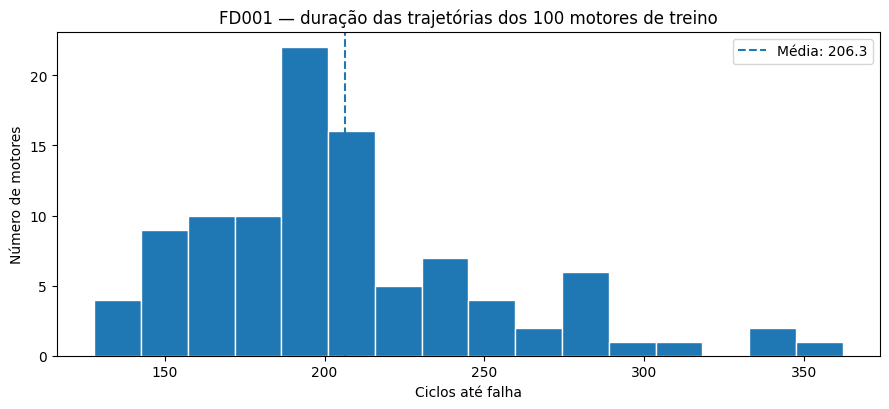

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000


In [15]:
# (2) Quantidade de ciclos observados por motor (trajetórias completas do treino).
ciclos_por_motor = train_df.groupby('unit_id')['cycle'].max()
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(ciclos_por_motor, bins=16, edgecolor='white')
ax.set(title='FD001 — duração das trajetórias dos 100 motores de treino',
       xlabel='Ciclos até falha', ylabel='Número de motores')
ax.axvline(ciclos_por_motor.mean(), linestyle='--', label=f'Média: {ciclos_por_motor.mean():.1f}')
ax.legend()
fig.tight_layout()
exibir_e_salvar(fig, 'eda_histograma_ciclos')
print(ciclos_por_motor.describe().to_string())

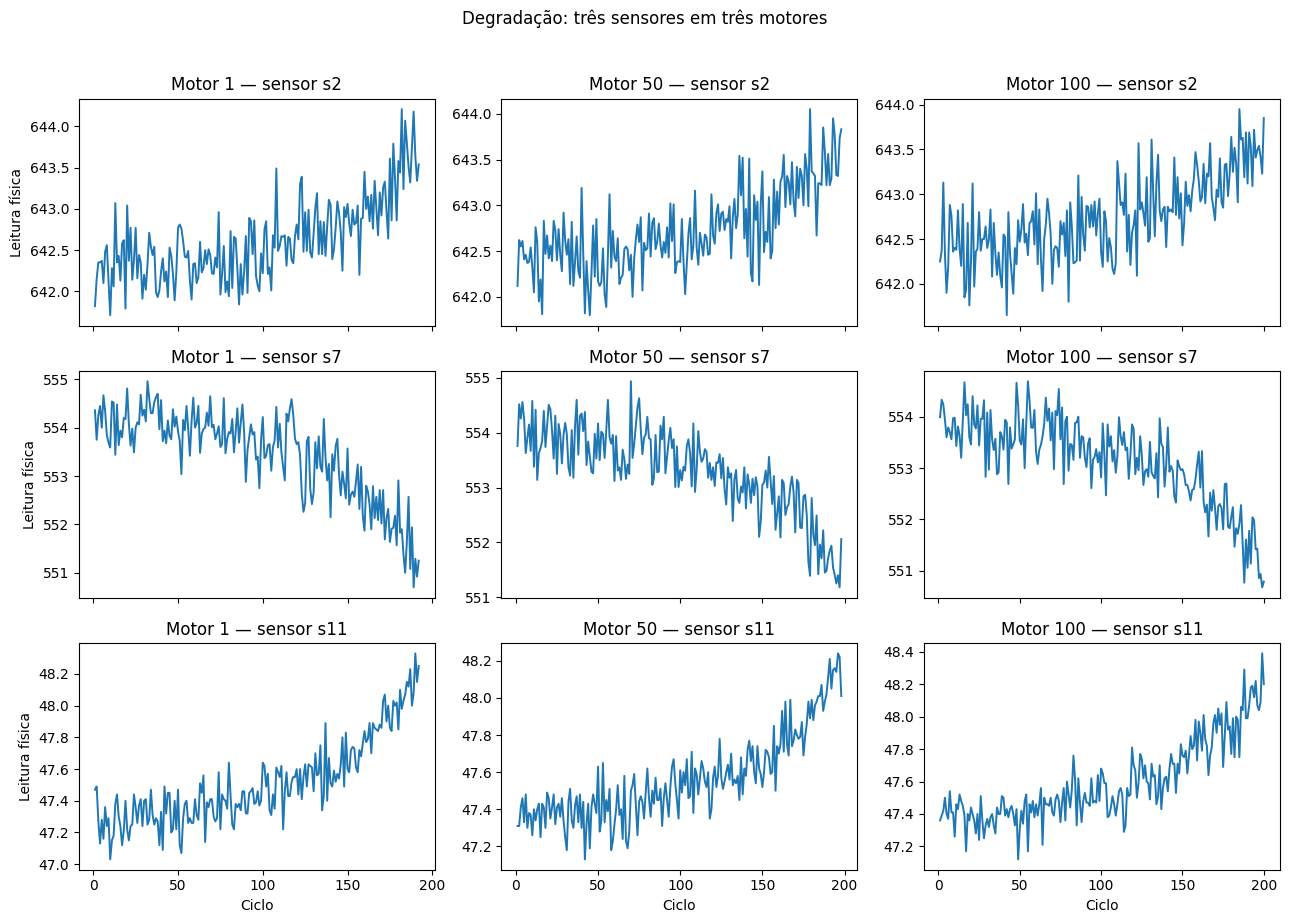

In [16]:
# (3) Evolução temporal de três sensores para três motores diferentes.
MOTORES_EDA = [1, 50, 100]
SENSORES_EDA = ['s2', 's7', 's11']
fig, axs = plt.subplots(3, 3, figsize=(13, 9), sharex='col')
for coluna, motor in enumerate(MOTORES_EDA):
    dados = train_df.loc[train_df.unit_id == motor]
    for linha, sensor in enumerate(SENSORES_EDA):
        ax = axs[linha, coluna]
        ax.plot(dados['cycle'], dados[sensor], linewidth=1.4)
        ax.set_title(f'Motor {motor} — sensor {sensor}')
        if linha == 2:
            ax.set_xlabel('Ciclo')
        if coluna == 0:
            ax.set_ylabel('Leitura física')
fig.suptitle('Degradação: três sensores em três motores', y=1.02)
fig.tight_layout()
exibir_e_salvar(fig, 'eda_series_temporais')

### Figura inspirada em Heimes (2008), Figura 1 — sinais no tempo e no espaço de estados

A apresentação combina **dois sensores ao longo dos ciclos** e a relação entre suas leituras no plano de fases. Este gráfico utiliza **um motor real do FD001**, não os sinais originais do artigo. No artigo de Heimes, há múltiplas condições operacionais; aqui o FD001 apresenta **uma condição**, portanto **não** se espera reproduzir seus seis agrupamentos de operação.

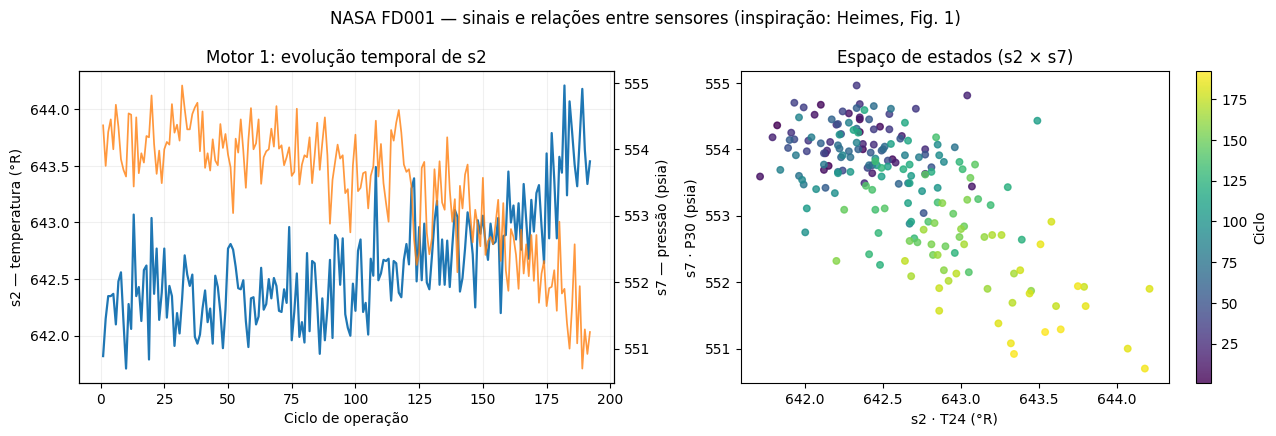

In [17]:
# Correspondência conceitual com Heimes (2008), Figura 1.
motor_fig1 = 1
serie_fig1 = train_df.loc[train_df.unit_id == motor_fig1].sort_values('cycle')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(serie_fig1.cycle, serie_fig1.s2, label='s2 · temperatura T24', lw=1.6)
axes[0].set(xlabel='Ciclo de operação', ylabel='s2 — temperatura (°R)',
            title=f'Motor {motor_fig1}: evolução temporal de s2')
ax2 = axes[0].twinx()
ax2.plot(serie_fig1.cycle, serie_fig1.s7, label='s7 · pressão P30',
         color='tab:orange', lw=1.25, alpha=0.8)
ax2.set_ylabel('s7 — pressão (psia)')
axes[0].grid(alpha=.18)
axes[1].scatter(serie_fig1.s2, serie_fig1.s7, c=serie_fig1.cycle,
                cmap='viridis', s=22, alpha=.8)
pontos = axes[1].collections[0]
fig.colorbar(pontos, ax=axes[1], label='Ciclo')
axes[1].set(xlabel='s2 · T24 (°R)', ylabel='s7 · P30 (psia)',
            title='Espaço de estados (s2 × s7)')
fig.suptitle('NASA FD001 — sinais e relações entre sensores (inspiração: Heimes, Fig. 1)')
fig.tight_layout()
exibir_e_salvar(fig, 'ref_heimes_fig1_sinais_fase')


Sensores estritamente constantes: ['s1', 's5', 's10', 's16', 's18', 's19']
Sensor adicional quase constante: ['s6']
Sete sensores removidos: ['s1', 's5', 's10', 's16', 's18', 's19', 's6']
14 sensores preservados: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
s6: valores observados = [np.float64(21.6), np.float64(21.61)] | variância = 1.9291855741275217e-06


,Sensor,Variância,N valores distintos,Decisão
0,s1,4.273228e-21,1,Constante
1,s2,2.500412e-01,310,Informativo
2,s3,3.758917e+01,3012,Informativo
3,s4,8.100696e+01,4051,Informativo
4,s5,1.152343e-23,1,Constante
5,s6,1.929186e-06,2,Quase constante
6,s7,7.833503e-01,513,Informativo
7,s8,5.038694e-03,53,Informativo
8,s9,4.876299e+02,6403,Informativo
9,s10,2.172228e-25,1,Constante


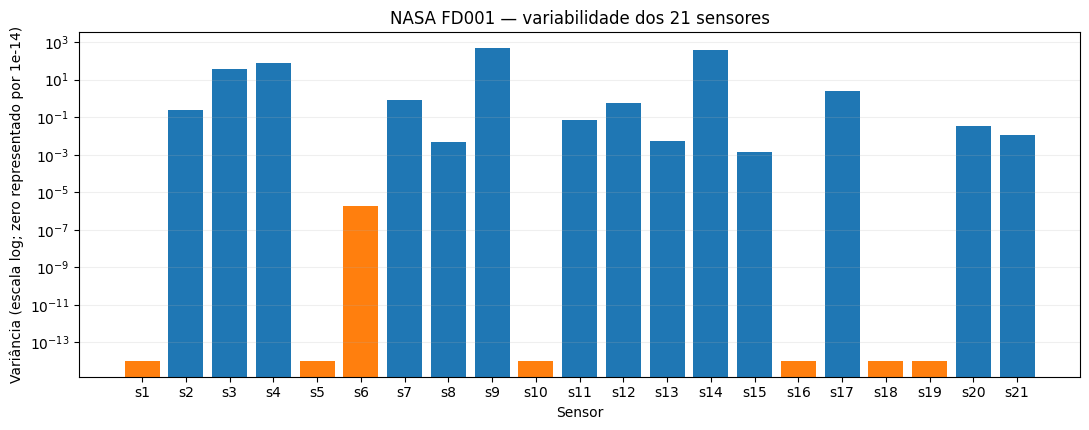

In [18]:
# (4) O FD001 original possui 6 sensores rigorosamente constantes e s6
# quase constante (somente 21.60 e 21.61). O enunciado pede remover 7.
# Por transparência, especificamos o 7º com base em sua baixa informação.
variancias = train_df[TODOS_SENSORES].var(ddof=0)
valores_unicos = train_df[TODOS_SENSORES].nunique()
CONSTANTES_EXATOS = [s for s in TODOS_SENSORES if valores_unicos[s] == 1]
QUASE_CONSTANTES = ['s6']  # s6: var ~1.93e-6, apenas dois valores, 21.60 e 21.61
SENSORES_CONSTANTES = CONSTANTES_EXATOS + QUASE_CONSTANTES
SENSORES_UTEIS = [s for s in TODOS_SENSORES if s not in SENSORES_CONSTANTES]
assert set(CONSTANTES_EXATOS) == {'s1', 's5', 's10', 's16', 's18', 's19'}, CONSTANTES_EXATOS
assert valores_unicos['s6'] == 2
assert len(SENSORES_CONSTANTES) == 7 and len(SENSORES_UTEIS) == 14
print('Sensores estritamente constantes:', CONSTANTES_EXATOS)
print('Sensor adicional quase constante:', QUASE_CONSTANTES)
print('Sete sensores removidos:', SENSORES_CONSTANTES)
print('14 sensores preservados:', SENSORES_UTEIS)
print('s6: valores observados =', sorted(train_df.s6.unique()),
      '| variância =', float(variancias['s6']))
status = ['Constante' if s in CONSTANTES_EXATOS else
          'Quase constante' if s in QUASE_CONSTANTES else 'Informativo'
          for s in TODOS_SENSORES]
resumo_sensores = pd.DataFrame({'Sensor': TODOS_SENSORES,
                               'Variância': variancias.to_numpy(),
                               'N valores distintos': valores_unicos.to_numpy(),
                               'Decisão': status})
display(resumo_sensores)
fig, ax = plt.subplots(figsize=(11, 4.4))
cores = ['tab:orange' if s in SENSORES_CONSTANTES else 'tab:blue'
         for s in TODOS_SENSORES]
ax.bar(TODOS_SENSORES, np.maximum(variancias.to_numpy(), 1e-14), color=cores)
ax.set(yscale='log', ylabel='Variância (escala log; zero representado por 1e-14)',
       xlabel='Sensor', title='NASA FD001 — variabilidade dos 21 sensores')
ax.grid(axis='y', alpha=.2)
fig.tight_layout()
exibir_e_salvar(fig, 'eda_variancias')


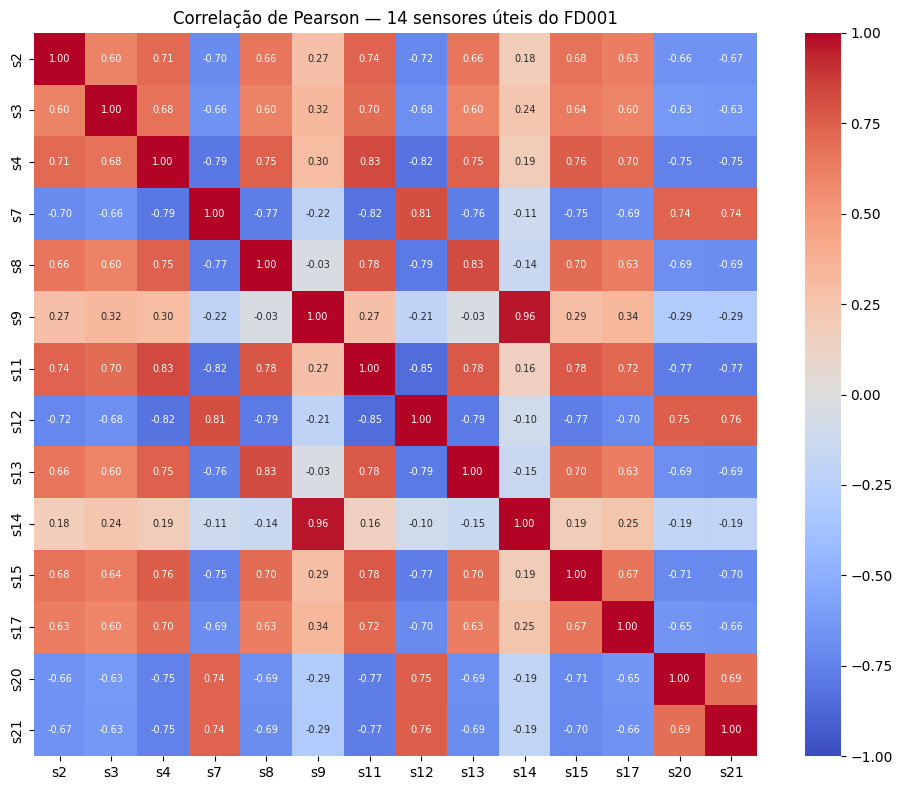

In [19]:
# (5) Correlação entre os 14 sensores úteis, sem incluir rótulos ou unit_id.
matriz_corr = train_df[SENSORES_UTEIS].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(matriz_corr, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', square=True, ax=ax, annot_kws={'size': 7})
ax.set_title('Correlação de Pearson — 14 sensores úteis do FD001')
fig.tight_layout()
exibir_e_salvar(fig, 'eda_correlacao_14_sensores')

## Etapa 2 — Pré-processamento e janelas deslizantes

**Itens 6 a 11.** Remover `unit_id` das features e os **sete sensores constantes**. Calcular RUL de **cada ciclo** das trajetórias completas: `RUL(t) = ciclo_de_falha − t`; usar `min(RUL,130)` para rótulos de treino e validação. Separar **80 motores / 20 motores** antes de ajustar o `MinMaxScaler`, evitando que qualquer registro de validação ou teste influencie mínimos e máximos. A janela de **W ciclos** tem shape `(W,14)` e o alvo corresponde **ao último ciclo** da janela. Para o teste oficial, construir **apenas uma janela final por motor**, preenchendo à esquerda com a primeira observação se a trajetória for mais curta que `W`.

**Escolha inicial:** `W=30` captura histórico recente e limita o custo de treinamento; o Optuna examinará `W ∈ {20,30,40,50}`. A janela influencia o contexto temporal, memória e quantidade de amostras (janelas maiores reduzem o número de exemplos por motor).

In [20]:
# (6, 8, 9, 11) RUL e partição por unidade COMPLETA (antes de escalar).
train_df['RUL_real'] = train_df.groupby('unit_id')['cycle'].transform('max') - train_df['cycle']
train_df['RUL_modelo'] = train_df['RUL_real'].clip(upper=RUL_MAX).astype('float32')

motores = np.sort(train_df.unit_id.unique())
ids_treino, ids_val = train_test_split(motores, test_size=0.2, random_state=SEED, shuffle=True)
assert len(ids_treino) == 80 and len(ids_val) == 20
assert len(set(ids_treino) & set(ids_val)) == 0

df_treino = train_df[train_df.unit_id.isin(ids_treino)].copy()
df_val = train_df[train_df.unit_id.isin(ids_val)].copy()
print(f'Motores treino: {len(ids_treino)} | motores validação: {len(ids_val)}')
print(f'Linhas treino: {len(df_treino):,} | linhas validação: {len(df_val):,}')
print('RUL original (exemplos):')
display(train_df[['unit_id','cycle','RUL_real','RUL_modelo']].head())

Motores treino: 80 | motores validação: 20
Linhas treino: 16,561 | linhas validação: 4,070
RUL original (exemplos):


,unit_id,cycle,RUL_real,RUL_modelo
0,1,1,191,130.0
1,1,2,190,130.0
2,1,3,189,130.0
3,1,4,188,130.0
4,1,5,187,130.0


### Figura inspirada em Heimes (2008), Figuras 2 e 3 — RUL completo e alvo limitado

A curva azul representa o RUL físico calculado nas trajetórias completas. A linha laranja ilustra a decisão de treinamento indicada pelo enunciado, `min(RUL, 130)`. **É apenas o alvo de treinamento**; os rótulos oficiais dos motores de teste continuam **sem clipping**.

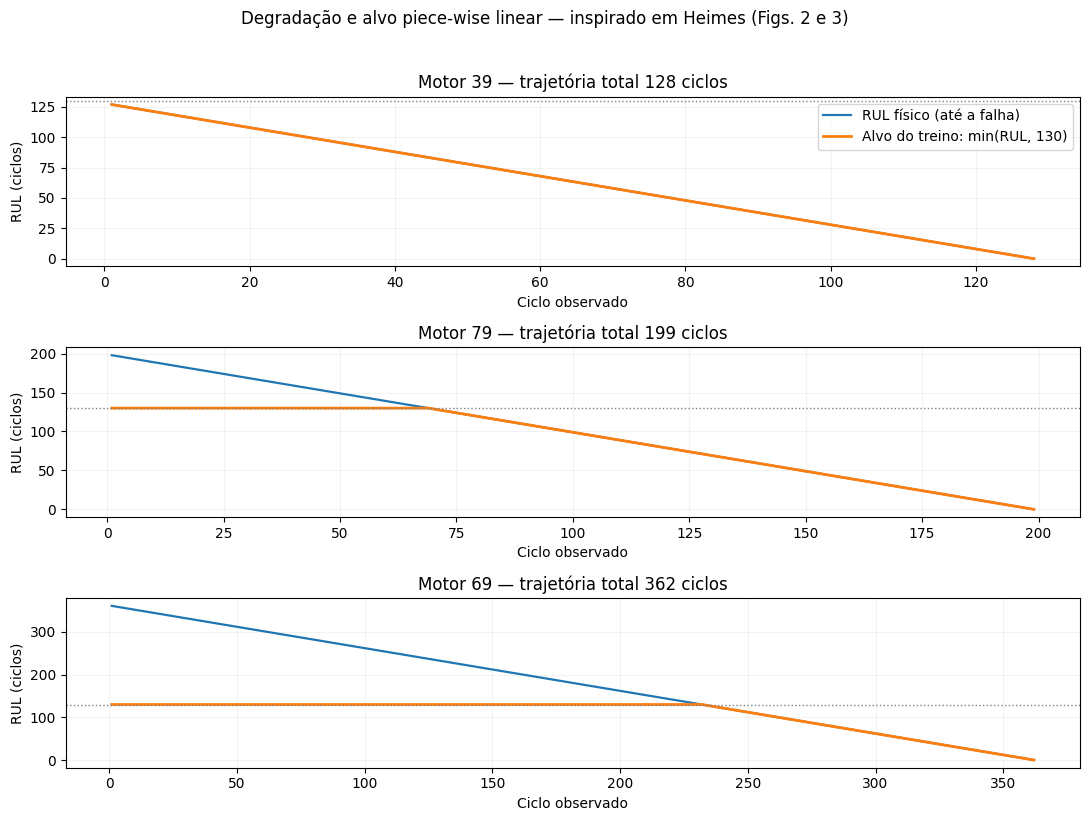

In [21]:
# Selecionar a trajetória mais curta, uma mediana e a mais longa do treino.
duracoes = train_df.groupby('unit_id')['cycle'].max().sort_values()
selecionados_rul = [int(duracoes.index[0]), int(duracoes.index[len(duracoes)//2]),
                    int(duracoes.index[-1])]
fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=False)
for ax, motor in zip(axs, selecionados_rul):
    dados = train_df.loc[train_df.unit_id == motor]
    ax.plot(dados.cycle, dados.RUL_real, color='tab:blue', lw=1.6,
            label='RUL físico (até a falha)')
    ax.plot(dados.cycle, dados.RUL_modelo, color='tab:orange', lw=2,
            label='Alvo do treino: min(RUL, 130)')
    ax.axhline(130, color='gray', ls=':', lw=1)
    ax.set(title=f'Motor {motor} — trajetória total {int(duracoes[motor])} ciclos',
           xlabel='Ciclo observado', ylabel='RUL (ciclos)')
    ax.grid(alpha=.15)
axs[0].legend(loc='upper right')
fig.suptitle('Degradação e alvo piece-wise linear — inspirado em Heimes (Figs. 2 e 3)', y=1.02)
fig.tight_layout()
exibir_e_salvar(fig, 'ref_heimes_rul_sem_e_com_clipping')


In [22]:
# (7) Ajuste do MinMaxScaler SOMENTE nos 80 motores de treinamento.
scaler = MinMaxScaler()
scaler.fit(df_treino[SENSORES_UTEIS].astype('float32'))
for d in (df_treino, df_val, test_df):
    # Conversão explícita evita advertências Pandas em sensores originalmente inteiros.
    d[SENSORES_UTEIS] = d[SENSORES_UTEIS].astype('float32')
    d[SENSORES_UTEIS] = scaler.transform(d[SENSORES_UTEIS]).astype('float32')
print('Features utilizadas:', len(SENSORES_UTEIS), SENSORES_UTEIS)
print('Intervalo normalizado do TREINO:',
      float(df_treino[SENSORES_UTEIS].min().min()),
      float(df_treino[SENSORES_UTEIS].max().max()))

Features utilizadas: 14 ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
Intervalo normalizado do TREINO: 0.0 1.0


In [23]:
# (10) Janelas deslizantes, com previsão do RUL no ÚLTIMO ciclo da janela.
def construir_janelas(df, W, sensores=SENSORES_UTEIS, target='RUL_modelo'):
    janelas, alvos, motores_da_janela, ciclos_finais = [], [], [], []
    for motor, fatia in df.groupby('unit_id', sort=True):
        fatia = fatia.sort_values('cycle')
        valores = fatia[sensores].to_numpy(dtype=np.float32)
        rotulos = fatia[target].to_numpy(dtype=np.float32)
        ciclos = fatia['cycle'].to_numpy()
        for fim in range(W - 1, len(fatia)):
            janelas.append(valores[fim - W + 1: fim + 1])
            alvos.append(rotulos[fim])
            motores_da_janela.append(motor)
            ciclos_finais.append(ciclos[fim])
    if not janelas:
        raise ValueError('Nenhuma janela gerada; escolha um W menor.')
    return (np.stack(janelas).astype('float32'), np.asarray(alvos, dtype='float32'),
            np.asarray(motores_da_janela), np.asarray(ciclos_finais))

# Treino e validação podem gerar várias janelas por motor.
X_train_base, y_train_base, grupos_treino, ciclos_treino = construir_janelas(df_treino, W_BASE)
X_val_base, y_val_base, grupos_val, ciclos_val = construir_janelas(df_val, W_BASE)
assert X_train_base.shape[1:] == (W_BASE, 14)
assert set(grupos_treino).isdisjoint(set(grupos_val))
print('Treino:', X_train_base.shape, 'Validação:', X_val_base.shape)
print('Exemplo de rótulo:', y_train_base[0], '(RUL em ciclos no último ponto da janela)')

Treino: (14241, 30, 14) Validação: (3490, 30, 14)
Exemplo de rótulo: 130.0 (RUL em ciclos no último ponto da janela)


In [24]:
# Teste oficial: uma ÚNICA janela final por motor e RUL original sem clipping.
def construir_janelas_teste(df, W, sensores=SENSORES_UTEIS):
    janelas, ids, ciclos = [], [], []
    for motor, fatia in df.groupby('unit_id', sort=True):
        fatia = fatia.sort_values('cycle')
        valores = fatia[sensores].to_numpy(dtype=np.float32)
        if len(valores) < W:
            preenchimento = np.repeat(valores[:1], W-len(valores), axis=0)
            valores = np.concatenate([preenchimento, valores], axis=0)
        janelas.append(valores[-W:])
        ids.append(motor)
        ciclos.append(fatia.cycle.iloc[-1])
    return np.stack(janelas).astype('float32'), np.asarray(ids), np.asarray(ciclos)

X_test_base, ids_test_base, ciclos_test_base = construir_janelas_teste(test_df, W_BASE)
assert X_test_base.shape == (100, W_BASE, 14)
assert np.array_equal(ids_test_base, ids_teste)
print('Teste:', X_test_base.shape, '| alvo oficial por motor:', rul_test.shape)

Teste: (100, 30, 14) | alvo oficial por motor: (100,)


### Visualização da entrada recorrente

Uma amostra de treinamento corresponde a uma **matriz temporal de W ciclos × 14 sensores**. A RNN prediz o RUL do **último ciclo**. O mapa abaixo exibe valores **já normalizados** com o `MinMaxScaler` ajustado exclusivamente nos motores de treino.

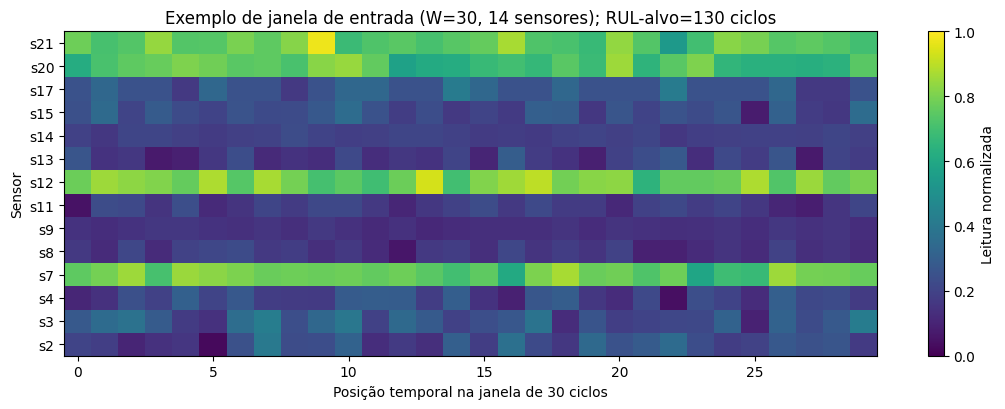

In [25]:
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(X_train_base[0].T, aspect='auto', origin='lower',
               cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
ax.set(yticks=range(14), yticklabels=SENSORES_UTEIS,
       xlabel=f'Posição temporal na janela de {W_BASE} ciclos', ylabel='Sensor',
       title=f'Exemplo de janela de entrada (W={W_BASE}, 14 sensores); RUL-alvo={y_train_base[0]:.0f} ciclos')
fig.colorbar(im, ax=ax, label='Leitura normalizada')
fig.tight_layout()
exibir_e_salvar(fig, 'janela_w14_mapa_calor')


## Etapa 3 — Arquitetura do modelo recorrente

**Itens 12 a 20.** Treinar uma LSTM de referência antes da busca (LSTM→Dense ReLU→Dense linear) e, no Optuna, explorar **SimpleRNN, LSTM e GRU**, **1 a 3** camadas recorrentes, tamanhos e dropout. Em pilhas recorrentes, `return_sequences=True` em **todas as camadas intermediárias** e `False` na última. A saída é **`Dense(1, activation='linear')`**, com otimização **Adam** e perda **MSE**. Dropout regulariza a representação temporal e a cabeça Dense agrega padrões de degradação.

A LSTM inicial é uma referência interpretável para comparar o efeito da busca: `64 unidades`, `1 camada`, `Dense(32, ReLU)`, `dropout=0,20`, `learning_rate=0,001`, `W=30`. Não há camadas de classificação nem softmax.

In [26]:
# Função reutilizável de arquitetura — usada na etapa 4 e em todos os trials da etapa 5.
def criar_rnn(W, n_features=14, cell_type='LSTM', n_layers=1, units=64,
              dropout=0.20, learning_rate=1e-3, dense_units=32):
    tipo = {'SimpleRNN': layers.SimpleRNN, 'LSTM': layers.LSTM, 'GRU': layers.GRU}[cell_type]
    model = keras.Sequential(name=f'RUL_{cell_type}_{n_layers}camadas_W{W}')
    model.add(layers.Input(shape=(W, n_features)))
    for i in range(n_layers):
        model.add(tipo(units, return_sequences=(i < n_layers-1), name=f'{cell_type.lower()}_{i+1}'))
        if dropout > 0:
            model.add(layers.Dropout(dropout, name=f'dropout_{i+1}'))
    model.add(layers.Dense(dense_units, activation='relu', name='dense_relu'))
    model.add(layers.Dense(1, activation='linear', name='rul_linear'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='mean_squared_error', metrics=['mae'])
    return model

BASE_PARAMS = dict(cell_type='LSTM', n_layers=1, units=64, dropout=0.20,
                   learning_rate=1e-3, dense_units=32, W=W_BASE, batch_size=BATCH_BASE)
model_baseline = criar_rnn(W=W_BASE, cell_type='LSTM', n_layers=1, units=64,
                           dropout=0.20, learning_rate=1e-3, dense_units=32)
model_baseline.summary()
print('Parâmetros totais:', model_baseline.count_params())
print('Parâmetros treináveis:', sum(int(np.prod(v.shape)) for v in model_baseline.trainable_weights))
print('Parâmetros não treináveis:', sum(int(np.prod(v.shape)) for v in model_baseline.non_trainable_weights))

Model: "RUL_LSTM_1camadas_W30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 64)             │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_relu (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rul_linear (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,337 (87.25 KB)

 Trainable params: 22,337 (87.25 KB)

 Non-trainable params: 0 (0.00 B)

Parâmetros totais: 22337
Parâmetros treináveis: 22337
Parâmetros não treináveis: 0


## Etapa 4 — Treinamento, callbacks e curvas de perda

**Itens 21 a 24.** Treinar a referência com **EarlyStopping monitorando `val_loss`, paciência 12 e `restore_best_weights=True`**, **ReduceLROnPlateau** e **ModelCheckpoint (`save_best_only=True`)**. Plotar **MSE de treino e validação por época**. O modelo final otimizado receberá os mesmos callbacks, e será salvo em formato `.keras`.

Epoch 1/60
223/223 - 8s - 35ms/step - loss: 3472.8623 - mae: 49.3974 - val_loss: 1872.6604 - val_mae: 38.3035 - learning_rate: 0.0010
Epoch 2/60
223/223 - 4s - 19ms/step - loss: 1895.1188 - mae: 38.5330 - val_loss: 1839.9098 - val_mae: 38.0005 - learning_rate: 0.0010
Epoch 3/60
223/223 - 5s - 23ms/step - loss: 1692.9587 - mae: 36.4038 - val_loss: 979.4406 - val_mae: 28.1399 - learning_rate: 0.0010
Epoch 4/60
223/223 - 6s - 25ms/step - loss: 608.1142 - mae: 20.2801 - val_loss: 342.6801 - val_mae: 14.7830 - learning_rate: 0.0010
Epoch 5/60
223/223 - 4s - 20ms/step - loss: 427.7229 - mae: 16.2319 - val_loss: 225.7318 - val_mae: 11.9100 - learning_rate: 0.0010
Epoch 6/60
223/223 - 6s - 27ms/step - loss: 349.4977 - mae: 14.4637 - val_loss: 183.5677 - val_mae: 10.4386 - learning_rate: 0.0010
Epoch 7/60
223/223 - 5s - 21ms/step - loss: 311.9619 - mae: 13.5850 - val_loss: 284.7584 - val_mae: 12.7470 - learning_rate: 0.0010
Epoch 8/60
223/223 - 5s - 21ms/step - loss: 294.7882 - mae: 13.1705 - v

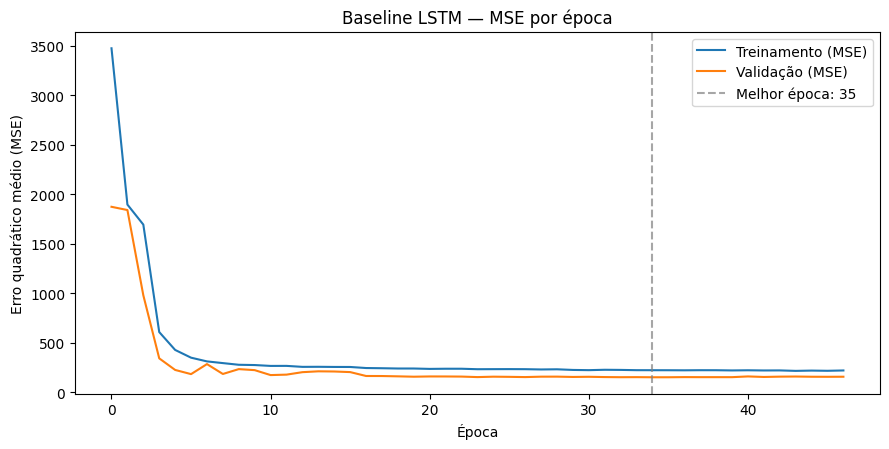

In [27]:
def criar_callbacks(caminho_modelo, paciencia_es=12):
    return [
        keras.callbacks.ModelCheckpoint(filepath=str(caminho_modelo), monitor='val_loss',
                                        mode='min', save_best_only=True, verbose=0),
        keras.callbacks.EarlyStopping(monitor='val_loss', mode='min',
                                      patience=paciencia_es, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', mode='min',
                                           factor=0.5, patience=5, min_lr=1e-6, verbose=0),
    ]

def plotar_perda(history, titulo, nome):
    fig, ax = plt.subplots(figsize=(9, 4.6))
    ax.plot(history.history['loss'], label='Treinamento (MSE)')
    ax.plot(history.history['val_loss'], label='Validação (MSE)')
    melhor_epoca = int(np.argmin(history.history['val_loss'])) + 1
    ax.axvline(melhor_epoca - 1, linestyle='--', color='gray', alpha=.7,
               label=f'Melhor época: {melhor_epoca}')
    ax.set(title=titulo, xlabel='Época', ylabel='Erro quadrático médio (MSE)')
    ax.legend()
    fig.tight_layout()
    exibir_e_salvar(fig, nome)

inicio = time.perf_counter()
BASELINE_PATH = OUT_DIR / 'modelo_baseline_FD001.keras'
history_baseline = model_baseline.fit(
    X_train_base, y_train_base,
    validation_data=(X_val_base, y_val_base),
    epochs=BASE_EPOCHS, batch_size=BATCH_BASE,
    callbacks=criar_callbacks(BASELINE_PATH), verbose=2, shuffle=True
)
tempo_baseline = time.perf_counter() - inicio
val_rmse_baseline = float(np.sqrt(min(history_baseline.history['val_loss'])))
print(f'RMSE validação (melhor época): {val_rmse_baseline:.3f} ciclos')
print(f'Tempo baseline: {tempo_baseline/60:.2f} min')
plotar_perda(history_baseline, 'Baseline LSTM — MSE por época', 'baseline_loss')

## Etapa 5 — Busca automática de hiperparâmetros com Optuna

**Enunciado:** `TPESampler` + `HyperbandPruner`. Pesquisa obrigatória: tipo de célula recorrente (`SimpleRNN`, `LSTM`, `GRU`), número de camadas, número de neurônios, `dropout`, taxa de aprendizagem e **tamanho da janela `W`**. Também serão pesquisados tamanho do lote e neurônios da camada Dense. Usaremos **o mesmo holdout por motor** em todos os trials: não é necessária validação cruzada nesta atividade.

**Pruning implementado:** callback comunica o **RMSE de validação por época** a `trial.report` e consulta `trial.should_prune()`. Quando há poda, a tentativa é interrompida antes do limite de épocas; não utiliza exemplos de teste. O objetivo reporta o menor RMSE de validação obtido no trial, coerente com o monitoramento do Hyperband. O *EarlyStopping* e o *ReduceLROnPlateau* continuam ativos durante a busca.

In [28]:
# Preparação de janelas de diferentes comprimentos, sem tocar nos motores de teste.
from functools import lru_cache

@lru_cache(maxsize=2)
def dados_para_W(W):
    Xtr, ytr, grp_tr, _ = construir_janelas(df_treino, W)
    Xva, yva, grp_va, _ = construir_janelas(df_val, W)
    assert set(grp_tr).isdisjoint(set(grp_va))
    return Xtr, ytr, Xva, yva

class PruningPorEpoca(keras.callbacks.Callback):
    def __init__(self, trial):
        super().__init__()
        self.trial = trial

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get('val_loss') is None:
            return
        rmse_intermediario = float(np.sqrt(max(0.0, logs['val_loss'])))
        self.trial.report(rmse_intermediario, step=epoch + 1)
        if self.trial.should_prune():
            raise optuna.TrialPruned(
                f'Hyperband interrompeu na época {epoch+1}: RMSE={rmse_intermediario:.4f}'
            )

sampler = optuna.samplers.TPESampler(seed=SEED)
pruner = optuna.pruners.HyperbandPruner(
    min_resource=3, max_resource=OPTUNA_EPOCHS, reduction_factor=3
)
study = optuna.create_study(direction='minimize', sampler=sampler,
                            pruner=pruner, study_name='FD001_RUL_TPE_Hyperband')

def objetivo(trial):
    params = {
        'cell_type': trial.suggest_categorical('cell_type', ['SimpleRNN', 'LSTM', 'GRU']),
        'n_layers': trial.suggest_int('n_layers', 1, 3),
        'units': trial.suggest_categorical('units', [32, 64, 96]),
        'dropout': trial.suggest_categorical('dropout', [0.1, 0.2, 0.3, 0.4]),
        'learning_rate': trial.suggest_float('learning_rate', 1e-4, 3e-3, log=True),
        'W': trial.suggest_categorical('W', [20, 30, 40, 50]),
        'dense_units': trial.suggest_categorical('dense_units', [32, 64]),
        'batch_size': trial.suggest_categorical('batch_size', [32, 64]),
    }
    Xtr, ytr, Xva, yva = dados_para_W(params['W'])
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED + trial.number)
    modelo = criar_rnn(W=params['W'], n_features=14, cell_type=params['cell_type'],
                      n_layers=params['n_layers'], units=params['units'],
                      dropout=params['dropout'], learning_rate=params['learning_rate'],
                      dense_units=params['dense_units'])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=12,
                                      restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=5,
                                          factor=0.5, min_lr=1e-6),
        PruningPorEpoca(trial),
    ]
    try:
        historico = modelo.fit(Xtr, ytr, validation_data=(Xva, yva),
                               epochs=OPTUNA_EPOCHS, batch_size=params['batch_size'],
                               callbacks=callbacks, verbose=0, shuffle=True)
        score = float(np.sqrt(min(historico.history['val_loss'])))
        trial.set_user_attr('epocas_treinadas', len(historico.history['loss']))
        trial.set_user_attr('melhor_val_mse', float(min(historico.history['val_loss'])))
        return score
    finally:
        del modelo
        gc.collect()

# Reproduzir uma configuração simples entre os trials, além das sugestões do TPE.
study.enqueue_trial(BASE_PARAMS)
start_optuna = time.perf_counter()
study.optimize(objetivo, n_trials=N_TRIALS, timeout=OPTUNA_TIMEOUT,
               show_progress_bar=False, gc_after_trial=True)
tempo_optuna = time.perf_counter() - start_optuna

estados = study.trials_dataframe(attrs=('number','value','state','duration','params'))
estados.to_csv(OUT_DIR / 'optuna_trials_FD001.csv', index=False)
completos = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
podados = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]
if not completos:
    raise RuntimeError('Nenhum trial foi concluído; aumente N_TRIALS ou revise o pruner.')

best_params = dict(study.best_params)
print(f'Trials concluídos: {len(completos)} | podados: {len(podados)}')
print(f'Melhor RMSE de validação: {study.best_value:.4f} ciclos')
print('Melhores hiperparâmetros:', json.dumps(best_params, indent=2, ensure_ascii=False))
print(f'Tempo da busca: {tempo_optuna/60:.2f} min')
(OUT_DIR / 'melhores_hiperparametros_FD001.json').write_text(
    json.dumps(best_params, indent=2, ensure_ascii=False), encoding='utf-8'
)
display(estados.sort_values('value').head(10))

[I 2026-10-24 14:46:58,105] A new study created in memory with name: FD001_RUL_TPE_Hyperband
[I 2026-10-24 14:51:24,430] Trial 0 finished with value: 12.31728397899231 and parameters: {'cell_type': 'LSTM', 'n_layers': 1, 'units': 64, 'dropout': 0.2, 'learning_rate': 0.001, 'W': 30, 'dense_units': 32, 'batch_size': 64}. Best is trial 0 with value: 12.31728397899231.
[I 2026-10-24 14:55:39,570] Trial 1 pruned. Hyperband interrompeu na época 27: RMSE=14.9157
[I 2026-10-24 15:01:55,663] Trial 2 finished with value: 11.63650435666047 and parameters: {'cell_type': 'SimpleRNN', 'n_layers': 2, 'units': 64, 'dropout': 0.4, 'learning_rate': 0.0001786013788939711, 'W': 40, 'dense_units': 32, 'batch_size': 32}. Best is trial 2 with value: 11.63650435666047.
[I 2026-10-24 15:10:27,832] Trial 3 finished with value: 14.584616177765337 and parameters: {'cell_type': 'LSTM', 'n_layers': 3, 'units': 64, 'dropout': 0.4, 'learning_rate': 0.0013962563737015762, 'W': 20, 'dense_units': 64, 'batch_size': 64}.

Trials concluídos: 8 | podados: 12
Melhor RMSE de validação: 10.8555 ciclos
Melhores hiperparâmetros: {
  "cell_type": "LSTM",
  "n_layers": 2,
  "units": 64,
  "dropout": 0.4,
  "learning_rate": 0.0013015186051377348,
  "W": 50,
  "dense_units": 32,
  "batch_size": 32
}
Tempo da busca: 98.33 min


,number,value,state,duration,params_W,params_batch_size,params_cell_type,params_dense_units,params_dropout,params_learning_rate,params_n_layers,params_units
16,16,10.855476,COMPLETE,0 days 00:12:36.717644,50,32,LSTM,32,0.4,0.001302,2,64
19,19,11.163241,COMPLETE,0 days 00:16:25.702967,50,32,LSTM,32,0.3,0.001537,2,64
18,18,11.315412,COMPLETE,0 days 00:10:51.574961,50,32,LSTM,32,0.4,0.001646,2,64
15,15,11.387811,COMPLETE,0 days 00:07:03.114570,40,32,LSTM,32,0.4,0.000455,1,64
2,2,11.636504,COMPLETE,0 days 00:06:15.781307,40,32,SimpleRNN,32,0.4,0.000179,2,64
0,0,12.317284,COMPLETE,0 days 00:04:26.321522,30,64,LSTM,32,0.2,0.001000,1,64
4,4,12.361828,COMPLETE,0 days 00:13:55.447665,30,32,GRU,32,0.3,0.000197,2,64
17,17,14.178008,PRUNED,0 days 00:01:31.803562,50,32,LSTM,32,0.4,0.000425,1,64
3,3,14.584616,COMPLETE,0 days 00:08:31.849524,20,64,LSTM,64,0.4,0.001396,3,64
1,1,14.915701,PRUNED,0 days 00:04:14.861610,20,32,LSTM,64,0.1,0.002708,2,32


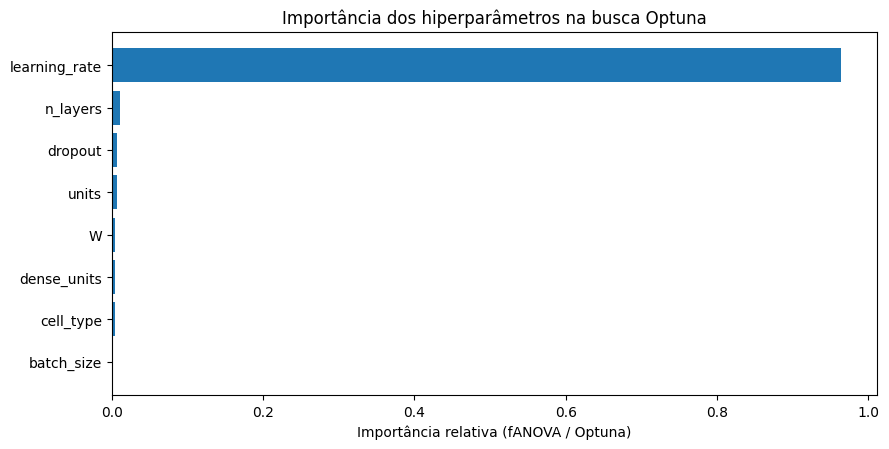

RMSE validação por comprimento da janela W (trials concluídos):


,count,mean,min
params_W,,,
20,1,14.585,14.585
30,2,12.340,12.317
40,2,11.512,11.388
50,3,11.111,10.855


RMSE validação por tipo de célula (trials concluídos):


,count,mean,min
params_cell_type,,,
GRU,1,12.362,12.362
LSTM,6,11.937,10.855
SimpleRNN,1,11.637,11.637


Atenção: essas médias são descritivas de uma busca adaptativa, não uma análise causal.


In [29]:
# (Etapa 5) Análise da importância relativa dos hiperparâmetros.
try:
    importancias = optuna.importance.get_param_importances(study)
except Exception as err:
    print('Importância estatística indisponível para este conjunto de trials:', err)
    importancias = {}

fig, ax = plt.subplots(figsize=(9, 4.6))
if importancias:
    itens = sorted(importancias.items(), key=lambda x: x[1])
    ax.barh([a for a, _ in itens], [v for _, v in itens])
    ax.set_xlabel('Importância relativa (fANOVA / Optuna)')
else:
    ax.text(0.5, 0.5, 'Amostra de trials completos insuficiente para estimar importâncias',
            ha='center', va='center', transform=ax.transAxes, wrap=True)
    ax.set_xticks([]); ax.set_yticks([])
ax.set_title('Importância dos hiperparâmetros na busca Optuna')
fig.tight_layout()
exibir_e_salvar(fig, 'optuna_importancia')

# Análise exploratória do efeito da janela e da célula nos TRIALS CONCLUÍDOS.
trials_completos = estados[estados['state'].astype(str).str.contains('COMPLETE')].copy()
if len(trials_completos):
    print('RMSE validação por comprimento da janela W (trials concluídos):')
    display(trials_completos.groupby('params_W')['value'].agg(['count','mean','min']).round(3))
    print('RMSE validação por tipo de célula (trials concluídos):')
    display(trials_completos.groupby('params_cell_type')['value'].agg(['count','mean','min']).round(3))
print('Atenção: essas médias são descritivas de uma busca adaptativa, não uma análise causal.')

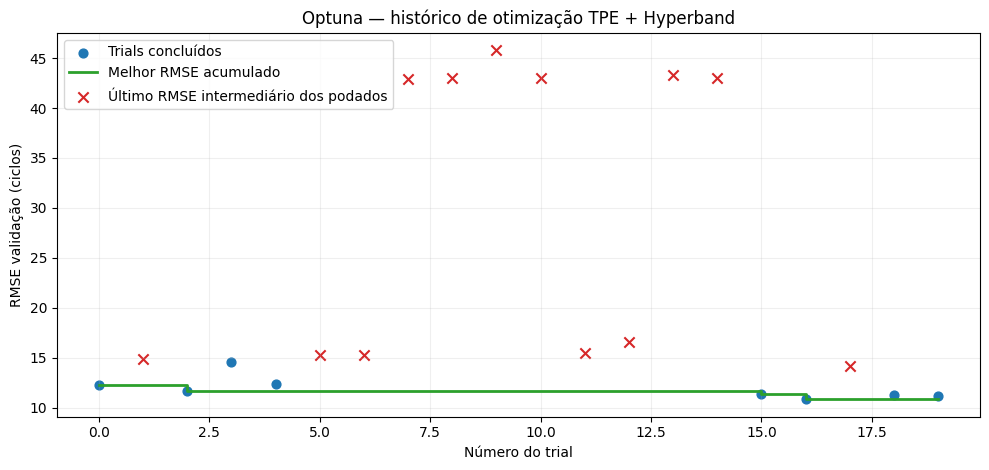

In [30]:
# Histórico da busca TPE/Hyperband: trials completos, melhores resultados
# acumulados e pontos podados (sem confundir pruning com score final).
trials_ok = sorted([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE],
                   key=lambda t: t.number)
trials_pruned = [t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED]
fig, ax = plt.subplots(figsize=(10, 4.8))
if trials_ok:
    nums = [t.number for t in trials_ok]
    vals = [t.value for t in trials_ok]
    ax.scatter(nums, vals, s=40, color='tab:blue', label='Trials concluídos')
    ax.step(nums, np.minimum.accumulate(vals), where='post', color='tab:green',
            lw=2, label='Melhor RMSE acumulado')
if trials_pruned:
    valores_prune = [(t.number, list(t.intermediate_values.values())[-1])
                     for t in trials_pruned if t.intermediate_values]
    if valores_prune:
        ax.scatter(*np.asarray(valores_prune).T, marker='x', s=55,
                   color='tab:red', label='Último RMSE intermediário dos podados')
ax.set(xlabel='Número do trial', ylabel='RMSE validação (ciclos)',
       title='Optuna — histórico de otimização TPE + Hyperband')
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
exibir_e_salvar(fig, 'optuna_historico_busca')


## Retreinamento do melhor modelo e salvamento para inferência

O modelo final é treinado **com os melhores hiperparâmetros encontrados apenas no conjunto de validação**, preservando 80/20 por motor e usando os mesmos callbacks obrigatórios. Mantemos um conjunto de validação separado para curvas, parada antecipada e checkpoint (não misturamos validação com treinamento). O checkpoint `.keras` resultante é a versão entregue para inferência. Ao utilizar esse modelo posteriormente, é imprescindível reaplicar os **14 sensores, o scaler e o tamanho W**, salvos junto com os metadados.

Model: "RUL_LSTM_2camadas_W50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50, 64)         │        20,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_relu (Dense)              │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rul_linear (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,361 (216.25 KB)

 Trainable params: 55,361 (216.25 KB)

 Non-trainable params: 0 (0.00 B)

Total params: 55361
Trainable params: 55361
Non-trainable params: 0
Epoch 1/90
396/396 - 25s - 62ms/step - loss: 2634.2715 - mae: 43.0753 - val_loss: 1819.6326 - val_mae: 37.4338 - learning_rate: 0.0013
Epoch 2/90
396/396 - 41s - 104ms/step - loss: 1885.3849 - mae: 38.0472 - val_loss: 1821.9011 - val_mae: 37.4390 - learning_rate: 0.0013
Epoch 3/90
396/396 - 20s - 51ms/step - loss: 1887.9851 - mae: 38.0775 - val_loss: 1797.1771 - val_mae: 37.2435 - learning_rate: 0.0013
Epoch 4/90
396/396 - 22s - 55ms/step - loss: 593.0311 - mae: 18.7488 - val_loss: 341.6532 - val_mae: 14.5069 - learning_rate: 0.0013
Epoch 5/90
396/396 - 20s - 51ms/step - loss: 304.8313 - mae: 13.1613 - val_loss: 181.9623 - val_mae: 10.6405 - learning_rate: 0.0013
Epoch 6/90
396/396 - 22s - 55ms/step - loss: 274.4048 - mae: 12.4064 - val_loss: 196.8519 - val_mae: 10.9311 - learning_rate: 0.0013
Epoch 7/90
396/396 - 21s - 54ms/step - loss: 266.3971 - mae: 12.2139 - val_loss: 164.5314 - val_mae: 9.7164 - learning_rate: 0.

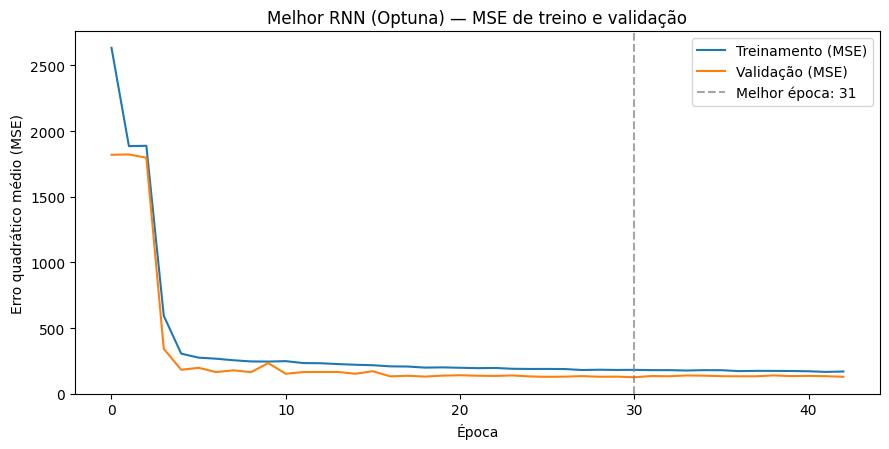

In [31]:
# Reexecutar o melhor ajuste do zero com seed fixa: pesos salvos são desse treinamento.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)
W_FINAL = int(best_params['W'])
X_train_final, y_train_final, X_val_final, y_val_final = dados_para_W(W_FINAL)
model_final = criar_rnn(
    W=W_FINAL,
    n_features=14,
    cell_type=best_params['cell_type'],
    n_layers=int(best_params['n_layers']),
    units=int(best_params['units']),
    dropout=float(best_params['dropout']),
    learning_rate=float(best_params['learning_rate']),
    dense_units=int(best_params['dense_units']),
)
model_final.summary()
print('Total params:', model_final.count_params())
print('Trainable params:', sum(int(np.prod(x.shape)) for x in model_final.trainable_weights))
print('Non-trainable params:', sum(int(np.prod(x.shape)) for x in model_final.non_trainable_weights))

MODELO_FINAL_PATH = OUT_DIR / 'melhor_modelo_FD001_RUL.keras'
start_final = time.perf_counter()
history_final = model_final.fit(
    X_train_final, y_train_final,
    validation_data=(X_val_final, y_val_final),
    batch_size=int(best_params['batch_size']), epochs=FINAL_EPOCHS,
    callbacks=criar_callbacks(MODELO_FINAL_PATH), verbose=2, shuffle=True
)
tempo_final = time.perf_counter() - start_final
model_final = keras.models.load_model(MODELO_FINAL_PATH)
assert MODELO_FINAL_PATH.is_file(), 'Checkpoint não foi salvo.'
print('Melhor modelo Keras:', MODELO_FINAL_PATH)
print(f'Melhor RMSE validação (treinamento final): {np.sqrt(min(history_final.history["val_loss"])):.3f}')
print(f'Duração treinamento final: {tempo_final/60:.2f} min')
plotar_perda(history_final, 'Melhor RNN (Optuna) — MSE de treino e validação', 'final_loss')

### Figura inspirada em Heimes (2008), Figura 4 — trajetórias reais × RNN prevista

Para três motores **exclusivos da validação** (curto, mediano e longo), comparamos o RUL real, o alvo com teto de 130 e a estimativa da melhor RNN. Diferentemente do artigo de Heimes, que usa uma arquitetura própria, esta é a **arquitetura Keras treinada neste notebook**. **Não é uma avaliação adicional do teste oficial.**

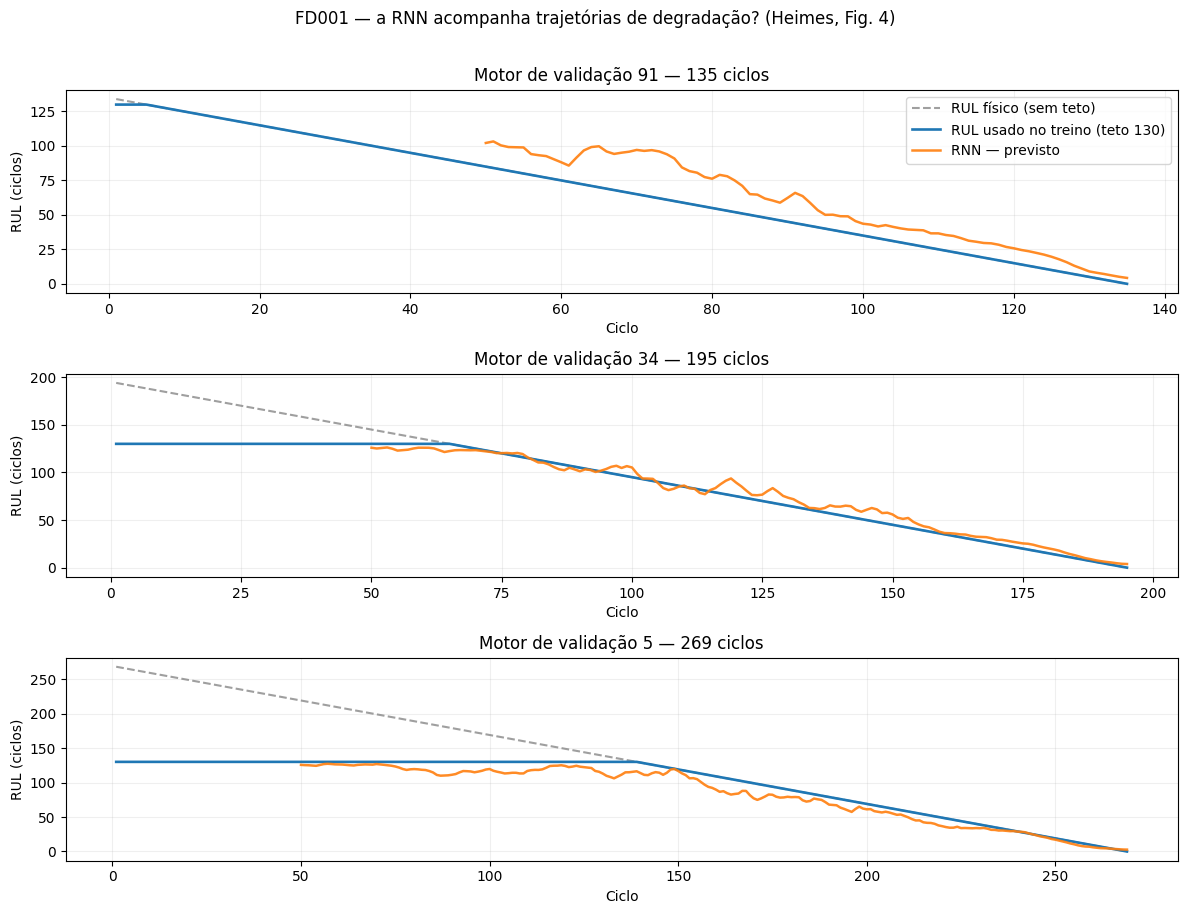

In [32]:
# Para visualização temporal, todos os pontos válidos das trajetórias de VALIDAÇÃO.
X_val_janelas, y_val_janelas, ids_val_janelas, ciclos_val_janelas = construir_janelas(df_val, W_FINAL)
pred_val_janelas = model_final.predict(
    X_val_janelas, batch_size=int(best_params['batch_size']), verbose=0
).reshape(-1)
comprimentos_val = df_val.groupby('unit_id')['cycle'].max().sort_values()
ids_fig4 = [int(comprimentos_val.index[0]),
            int(comprimentos_val.index[len(comprimentos_val)//2]),
            int(comprimentos_val.index[-1])]
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=False)
for ax, motor in zip(axes, ids_fig4):
    serie = df_val.loc[df_val.unit_id == motor].sort_values('cycle')
    mascara = (ids_val_janelas == motor)
    ax.plot(serie.cycle, serie.RUL_real, ls='--', color='tab:gray', alpha=.75,
            label='RUL físico (sem teto)')
    ax.plot(serie.cycle, serie.RUL_modelo, lw=1.9, color='tab:blue',
            label='RUL usado no treino (teto 130)')
    ax.plot(ciclos_val_janelas[mascara], pred_val_janelas[mascara], lw=1.8,
            color='tab:orange', alpha=.9, label='RNN — previsto')
    ax.set(title=f'Motor de validação {motor} — {int(comprimentos_val[motor])} ciclos',
           xlabel='Ciclo', ylabel='RUL (ciclos)')
    ax.grid(alpha=.2)
axes[0].legend(loc='upper right')
fig.suptitle('FD001 — a RNN acompanha trajetórias de degradação? (Heimes, Fig. 4)', y=1.01)
fig.tight_layout()
exibir_e_salvar(fig, 'ref_heimes_fig4_rnn_3_motores_validacao')


In [33]:
# Pré-processamento associado ao modelo salvo; necessário para inferência reproduzível.
import joblib
SCALER_PATH = OUT_DIR / 'minmax_fd001.joblib'
joblib.dump(scaler, SCALER_PATH)
config_inferencia = {
    'dataset': 'NASA C-MAPSS FD001',
    'features': SENSORES_UTEIS,
    'constant_sensors_removed': SENSORES_CONSTANTES,
    'window_size': W_FINAL,
    'rul_training_cap': RUL_MAX,
    'seed': SEED,
    'input_shape': [W_FINAL, len(SENSORES_UTEIS)],
    'target_unit': 'cycles',
    'best_parameters': best_params,
    'model_filename': MODELO_FINAL_PATH.name,
    'scaler_filename': SCALER_PATH.name,
}
(OUT_DIR / 'config_inferencia_FD001.json').write_text(
    json.dumps(config_inferencia, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Artefatos de inferência: .keras + .joblib + .json')

Artefatos de inferência: .keras + .joblib + .json


## Etapa 6 — Avaliação oficial e métricas de regressão

**Itens 25 a 29.** Fazer **uma previsão por cada um dos 100 motores oficiais**, usando a **última janela** de cada trajetória truncada. Avaliar contra as **100 RULs originais sem clipping** de `RUL_FD001.txt`. Métricas: RMSE, MAE e **NASA Score assimétrico com a fórmula impressa no PDF**: para `d = RUL_estimada − RUL_real`, aplicar `exp(−d/10)−1` se `d<0`, ou `exp(d/13)−1` se `d≥0`. **Score menor = melhor.** Esta escolha reproduz literalmente o enunciado, ainda que outras referências possam usar uma convenção de denominadores diferente.

In [34]:
# (25–27) Métricas em TODOS os 100 motores, nunca em uma amostra de janelas.
X_test_final, test_ids, test_ciclos = construir_janelas_teste(test_df, W_FINAL)
assert X_test_final.shape == (100, W_FINAL, 14)
assert np.array_equal(test_ids, ids_teste)
y_real = rul_test.astype('float64')  # Sem clipping no ground truth oficial.
y_prev = model_final.predict(X_test_final, batch_size=int(best_params['batch_size']), verbose=0).reshape(-1).astype('float64')
assert y_real.shape == y_prev.shape == (100,)

def nasa_score_pdf(y_true, y_pred):
    d = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    return float(np.where(d < 0, np.expm1(-d / 10), np.expm1(d / 13)).sum())

rmse_teste = float(np.sqrt(mean_squared_error(y_real, y_prev)))
mae_teste = float(mean_absolute_error(y_real, y_prev))
nasa_teste = nasa_score_pdf(y_real, y_prev)
print(f'RMSE oficial (100 motores): {rmse_teste:.4f} ciclos')
print(f'MAE oficial (100 motores):  {mae_teste:.4f} ciclos')
print(f'NASA Score — fórmula PDF:  {nasa_teste:.4f} (menor=melhor)')

predicoes = pd.DataFrame({
    'unit_id': test_ids, 'ultimo_ciclo_observado': test_ciclos,
    'RUL_real': y_real, 'RUL_previsto': y_prev,
})
predicoes['erro_assinado'] = predicoes['RUL_previsto'] - predicoes['RUL_real']
predicoes['erro_absoluto'] = predicoes['erro_assinado'].abs()
predicoes.to_csv(OUT_DIR / 'predicoes_FD001_100_motores.csv', index=False)
display(predicoes.head(12))

metricas = {
    'dataset': 'FD001', 'n_motores_teste': len(y_real),
    'rmse_teste': rmse_teste, 'mae_teste': mae_teste, 'nasa_score_pdf': nasa_teste,
    'rmse_val_baseline': val_rmse_baseline,
    'rmse_val_best_optuna': float(study.best_value),
    'rmse_val_final': float(np.sqrt(min(history_final.history['val_loss']))),
    'trials_total': len(study.trials), 'trials_completos': len(completos),
    'trials_podados': len(podados),
    'tempo_min_baseline': tempo_baseline/60,
    'tempo_min_optuna': tempo_optuna/60,
    'tempo_min_final': tempo_final/60,
}
(OUT_DIR/'metricas_FD001.json').write_text(
    json.dumps(metricas, indent=2, ensure_ascii=False), encoding='utf-8'
)

RMSE oficial (100 motores): 14.5169 ciclos
MAE oficial (100 motores):  10.7685 ciclos
NASA Score — fórmula PDF:  354.7062 (menor=melhor)


,unit_id,ultimo_ciclo_observado,RUL_real,RUL_previsto,erro_assinado,erro_absoluto
0,1,31,112.0,122.652390,10.652390,10.652390
1,2,49,98.0,116.031654,18.031654,18.031654
2,3,126,69.0,58.258957,-10.741043,10.741043
3,4,106,82.0,93.024780,11.024780,11.024780
4,5,98,91.0,98.605743,7.605743,7.605743
5,6,105,93.0,118.440514,25.440514,25.440514
6,7,160,91.0,97.830215,6.830215,6.830215
7,8,166,95.0,84.811348,-10.188652,10.188652
8,9,55,111.0,120.526665,9.526665,9.526665
9,10,192,96.0,83.077599,-12.922401,12.922401


481

### Figura inspirada em Saxena et al. (2008), Equação 9 e Figura 9 — NASA Score assimétrico

A métrica distingue o erro assinado `d = RUL_previsto − RUL_real`. Adotamos **exatamente os denominadores do enunciado** (`10` quando `d < 0`; `13` quando `d ≥ 0`). **Atenção interpretativa:** com essa fórmula, erros negativos de mesma magnitude têm penalização maior; isso não coincide literalmente com a motivação textual do artigo sobre penalizar mais previsões tardias. A fórmula do enunciado prevalece para a implementação, e a divergência é explicitada no relatório.

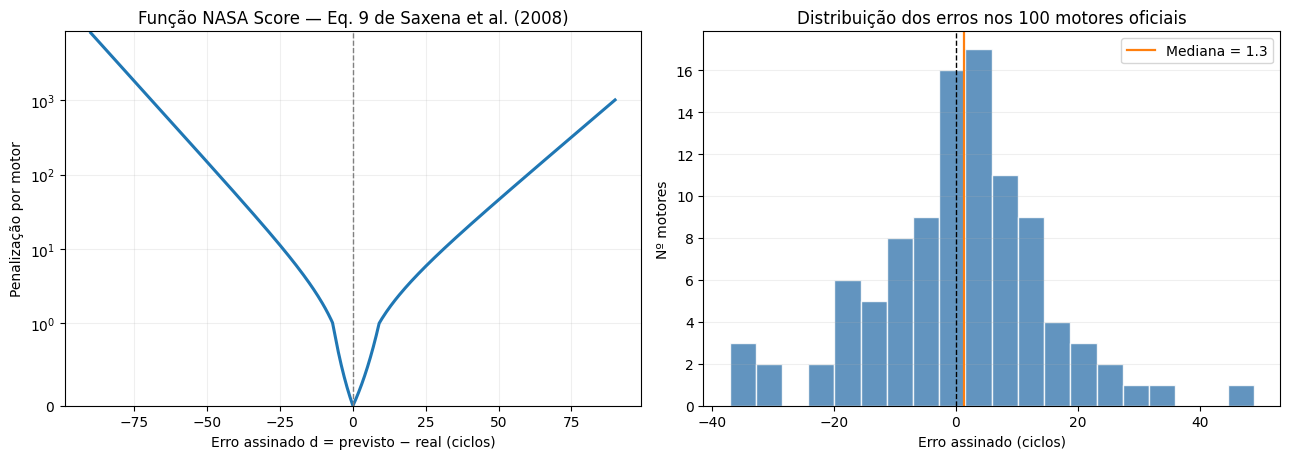

Composição da pontuação NASA por direção do erro:
  RUL subestimado (d < 0): 43 motores, soma de penalizações = 224.17
  RUL superestimado (d ≥ 0): 57 motores, soma de penalizações = 130.54


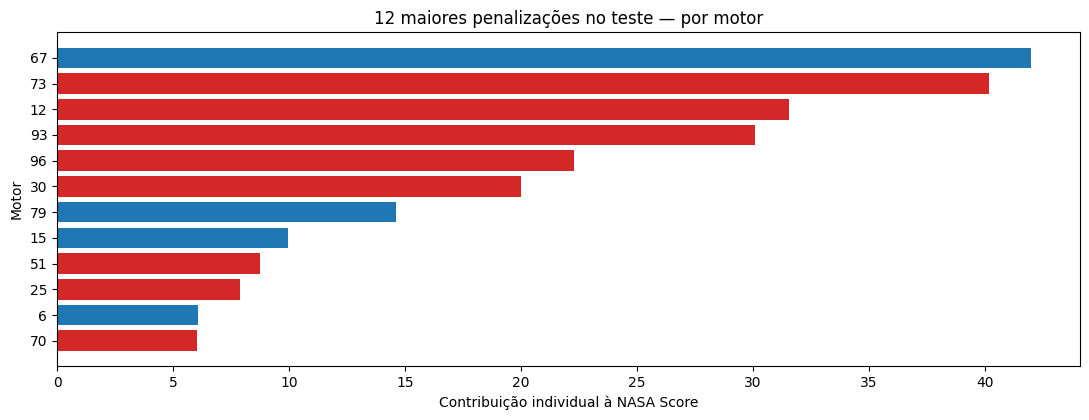

In [35]:
# A curva é teórica, enquanto as marcas representam os erros reais dos 100 motores.
erros_assinados = predicoes['erro_assinado'].to_numpy(dtype=float)
grade_erros = np.linspace(-90, 90, 361)
score_unitario = lambda d: np.where(d < 0, np.expm1(-d/10.0), np.expm1(d/13.0))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.7))
axs[0].plot(grade_erros, score_unitario(grade_erros), lw=2.2,
            label='Penalização assimétrica (NASA)')
axs[0].axvline(0, color='gray', lw=1, ls='--')
axs[0].set(xlabel='Erro assinado d = previsto − real (ciclos)',
           ylabel='Penalização por motor',
           title='Função NASA Score — Eq. 9 de Saxena et al. (2008)')
axs[0].set_yscale('symlog', linthresh=1)
axs[0].set_ylim(bottom=0)  # Score é sempre não negativo
axs[0].grid(alpha=.2)
axs[1].hist(erros_assinados, bins=20, color='steelblue', edgecolor='white', alpha=.85)
axs[1].axvline(0, color='black', lw=1, ls='--')
axs[1].axvline(np.median(erros_assinados), color='tab:orange', lw=1.6,
               label=f'Mediana = {np.median(erros_assinados):.1f}')
axs[1].set(xlabel='Erro assinado (ciclos)', ylabel='Nº motores',
           title='Distribuição dos erros nos 100 motores oficiais')
axs[1].legend(); axs[1].grid(axis='y', alpha=.2)
fig.tight_layout()
exibir_e_salvar(fig, 'ref_saxena_fig9_nasa_score')

# Exibir quais motores contribuem mais ao NASA Score (somente análise pós-teste).
predicoes['nasa_score_individual'] = score_unitario(erros_assinados)
print('Composição da pontuação NASA por direção do erro:')
for rotulo, filtro in [('RUL subestimado (d < 0)', erros_assinados < 0),
                       ('RUL superestimado (d ≥ 0)', erros_assinados >= 0)]:
    print(f'  {rotulo}: {int(np.sum(filtro))} motores, '
          f'soma de penalizações = {predicoes.loc[filtro, "nasa_score_individual"].sum():.2f}')
fig, ax = plt.subplots(figsize=(11, 4.3))
maiores = predicoes.nlargest(12, 'nasa_score_individual').sort_values('nasa_score_individual')
ax.barh(maiores['unit_id'].astype(str), maiores.nasa_score_individual,
        color=['tab:red' if d < 0 else 'tab:blue' for d in maiores.erro_assinado])
ax.set(xlabel='Contribuição individual à NASA Score', ylabel='Motor',
       title='12 maiores penalizações no teste — por motor')
fig.tight_layout()
exibir_e_salvar(fig, 'teste_maiores_penalizacoes_nasa')


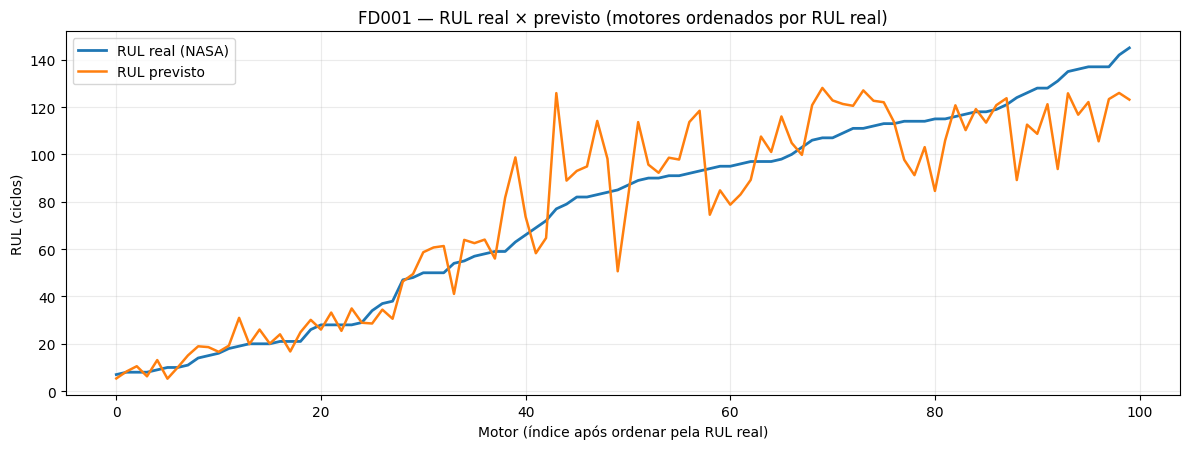

In [36]:
# (28) Curvas RUL real e previsto, ordenadas pelo RUL REAL (100 motores).
ordem = np.argsort(y_real)
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(np.arange(len(ordem)), y_real[ordem], label='RUL real (NASA)', linewidth=2)
ax.plot(np.arange(len(ordem)), y_prev[ordem], label='RUL previsto', linewidth=1.8)
ax.set(title='FD001 — RUL real × previsto (motores ordenados por RUL real)',
       xlabel='Motor (índice após ordenar pela RUL real)', ylabel='RUL (ciclos)')
ax.legend(); ax.grid(alpha=.25)
fig.tight_layout()
exibir_e_salvar(fig, 'teste_rul_real_vs_previsto')

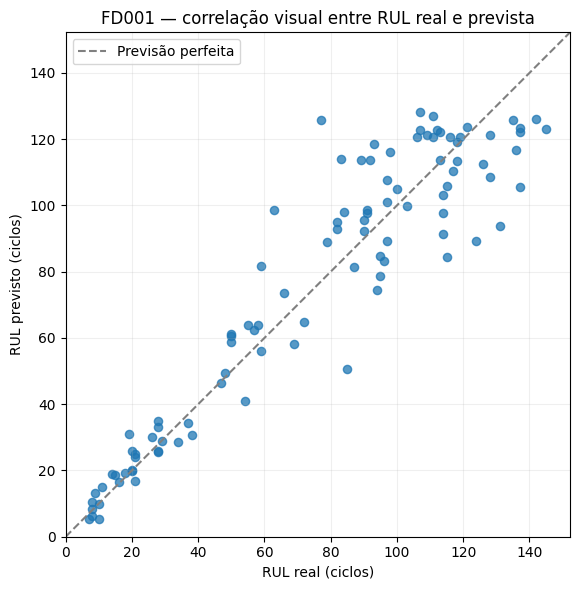

In [37]:
# (29) Scatter com diagonal de predição perfeita.
fig, ax = plt.subplots(figsize=(6.8, 6.0))
ax.scatter(y_real, y_prev, alpha=.75, s=35)
lim_min = min(0, float(y_real.min()), float(y_prev.min()))
lim_max = max(float(y_real.max()), float(y_prev.max())) * 1.05
ax.plot([lim_min, lim_max], [lim_min, lim_max], '--', color='gray', label='Previsão perfeita')
ax.set(xlabel='RUL real (ciclos)', ylabel='RUL previsto (ciclos)',
       title='FD001 — correlação visual entre RUL real e prevista',
       xlim=(lim_min, lim_max), ylim=(lim_min, lim_max))
ax.set_aspect('equal', adjustable='box'); ax.legend(); ax.grid(alpha=.2)
fig.tight_layout()
exibir_e_salvar(fig, 'teste_scatter_diagonal')

## Análise de erros e discussão crítica (critérios da Seção 7)

Responder **onde a RNN errou mais**, comparar referência versus modelo otimizado **na validação** (sem escolher com base no teste) e discutir a escolha de W e de tipo de célula. O desempenho do teste pode ser diferente do da validação, pois os alvos oficiais não são truncados em 130 e o modelo recebe trajetórias parciais.

Desempenho por faixa de RUL REAL:


,n_motores,MAE,vies_medio
faixa_RUL,,,
≤30 ciclos,25,3.19,1.82
31–80 ciclos,20,11.38,6.37
81–130 ciclos,47,12.89,0.77
>130 ciclos,8,20.44,-20.44


Cinco maiores erros absolutos (somente análise posterior ao teste):


,unit_id,ultimo_ciclo_observado,RUL_real,RUL_previsto,erro_assinado,erro_absoluto,nasa_score_individual,faixa_RUL
66,67,71,77.0,125.892670,48.892670,48.892670,41.990304,31–80 ciclos
72,73,112,131.0,93.821098,-37.178902,37.178902,40.177425,>130 ciclos
78,79,101,63.0,98.733673,35.733673,35.733673,14.622998,31–80 ciclos
11,12,217,124.0,89.167099,-34.832901,34.832901,31.566694,81–130 ciclos
92,93,244,85.0,50.632748,-34.367252,34.367252,30.084995,81–130 ciclos


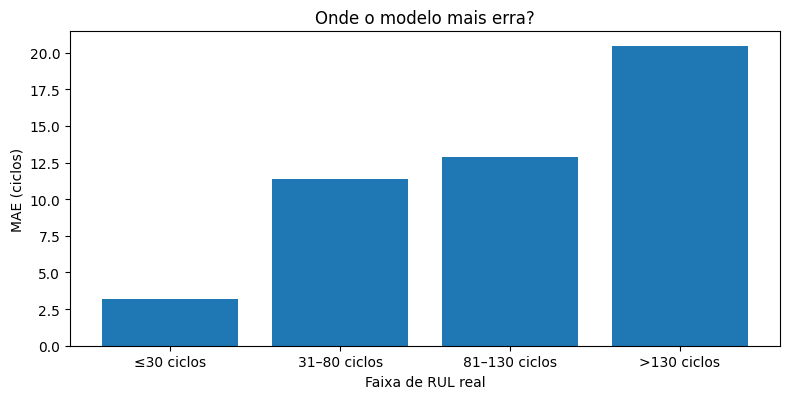


DISCUSSÃO PARA O RELATÓRIO:
• Baseline LSTM na validação: RMSE=12.32.
• Melhor trial Optuna na validação: RMSE=10.86.
• Melhores hiperparâmetros: {'cell_type': 'LSTM', 'n_layers': 2, 'units': 64, 'dropout': 0.4, 'learning_rate': 0.0013015186051377348, 'W': 50, 'dense_units': 32, 'batch_size': 32}
• No teste oficial: RMSE=14.52, MAE=10.77, NASA=354.71.
• Maior MAE por faixa: >130 ciclos.
• Compare os efeitos de W e tipo recorrente com os agrupamentos dos trials; não infira causalidade.
• Heimes (2008) sustenta o uso de memória temporal, mas usa arquitetura e treinamento diferentes.
• Saxena et al. (2008), Eq. 9: com d=previsto-real e a1=10/a2=13,
  erros negativos são mais penalizados que positivos de mesma magnitude,
  apesar da motivação textual do artigo sobre previsões tardias.


In [38]:
# Faixas de RUL permitem descrever os pontos fracos sem escolher hiperparâmetros com o teste.
faixas = [-np.inf, 30, 80, 130, np.inf]
rotulos_faixa = ['≤30 ciclos', '31–80 ciclos', '81–130 ciclos', '>130 ciclos']
predicoes['faixa_RUL'] = pd.cut(predicoes['RUL_real'], bins=faixas, labels=rotulos_faixa)
erros_faixa = (predicoes.groupby('faixa_RUL', observed=False)
               .agg(n_motores=('unit_id','count'), MAE=('erro_absoluto','mean'),
                    vies_medio=('erro_assinado','mean')))
print('Desempenho por faixa de RUL REAL:')
display(erros_faixa.round(2))
print('Cinco maiores erros absolutos (somente análise posterior ao teste):')
display(predicoes.nlargest(5, 'erro_absoluto'))
fig, ax = plt.subplots(figsize=(8, 4.1))
ax.bar(erros_faixa.index.astype(str), erros_faixa['MAE'])
ax.set(title='Onde o modelo mais erra?', ylabel='MAE (ciclos)', xlabel='Faixa de RUL real')
fig.tight_layout()
exibir_e_salvar(fig, 'teste_erro_por_faixa')

print('\nDISCUSSÃO PARA O RELATÓRIO:')
print(f'• Baseline LSTM na validação: RMSE={val_rmse_baseline:.2f}.')
print(f'• Melhor trial Optuna na validação: RMSE={study.best_value:.2f}.')
print(f'• Melhores hiperparâmetros: {best_params}')
print(f'• No teste oficial: RMSE={rmse_teste:.2f}, MAE={mae_teste:.2f}, NASA={nasa_teste:.2f}.')
print(f'• Maior MAE por faixa: {erros_faixa["MAE"].idxmax()}.')
print('• Compare os efeitos de W e tipo recorrente com os agrupamentos dos trials; não infira causalidade.')
print('• Heimes (2008) sustenta o uso de memória temporal, mas usa arquitetura e treinamento diferentes.')
print('• Saxena et al. (2008), Eq. 9: com d=previsto-real e a1=10/a2=13,')
print('  erros negativos são mais penalizados que positivos de mesma magnitude,')
print('  apesar da motivação textual do artigo sobre previsões tardias.')

## Entregáveis obrigatórios — Seção 8

1. **Notebook:** este `.ipynb`, executado do início ao fim, com EDA, arquitetura, callbacks, Optuna TPE/Hyperband, métricas e figuras.
2. **Relatório técnico de até 8 páginas:** a célula seguinte gera automaticamente o PDF `relatorio_tecnico_FD001.pdf`, preenchido com valores e gráficos **reais da execução**, para revisão do estudante. Não há valores simulados.
3. **Modelo salvo:** `melhor_modelo_FD001_RUL.keras`, acompanhado de `minmax_fd001.joblib` e `config_inferencia_FD001.json` para permitir inferência correta.

Após executar no Kaggle, procure os arquivos em `/kaggle/working/FD001_RNN_Resultados/`. Faça download desses três artefatos antes de encerrar a sessão. **Revise o relatório e acrescente sua discussão autoral sobre erros, escolha de W e célula recorrente antes da entrega.**

In [39]:
# Relatório automatizado de EXATAMENTE 8 páginas no máximo, com resultados reais.
# Implementado com matplotlib/PdfPages (sem dependência adicional de geração de PDFs).
RELATORIO_PATH = OUT_DIR / 'relatorio_tecnico_FD001.pdf'


def pagina_texto(titulo, linhas, subtitulo=None, tamanho=10.2):
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.patch.set_facecolor('white')
    fig.text(.08, .95, titulo, fontsize=18, weight='bold', va='top')
    if subtitulo:
        fig.text(.08, .918, subtitulo, fontsize=10, color='dimgray', va='top')
    y = .87
    for linha in linhas:
        if not linha:
            y -= .022
            continue
        for trecho in textwrap.wrap(str(linha), width=95, break_long_words=False):
            fig.text(.08, y, trecho, fontsize=tamanho, va='top')
            y -= .026
        y -= .016
        if y < .075:
            break
    fig.text(.08, .035, 'UFPE · Aprendizado de Máquina · FD001 · resultados desta execução', fontsize=8, color='gray')
    return fig


def pagina_figura(nome_figura, titulo, legenda):
    # Incorporar PNG gerado no notebook, incluindo eixos e legendas originais.
    imagem = plt.imread(FIG_DIR / f'{nome_figura}.png')
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.06, .957, titulo, fontsize=16, weight='bold', va='top')
    ax = fig.add_axes([.055, .18, .89, .70])
    ax.imshow(imagem)
    ax.axis('off')
    fig.text(.06, .13, textwrap.fill(legenda, 105), fontsize=9, va='top')
    fig.text(.06, .04, 'C-MAPSS FD001 — elaboração própria com os dados e experimentos', fontsize=8, color='gray')
    return fig

def pagina_figura(nome_figura, titulo, legenda):
    imagem = plt.imread(FIG_DIR / f'{nome_figura}.png')
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.06, .957, titulo, fontsize=16, weight='bold', va='top')
    ax = fig.add_axes([.055, .18, .89, .70])
    ax.imshow(imagem)
    ax.axis('off')
    fig.text(.06, .13, textwrap.fill(legenda, 105), fontsize=9, va='top')
    fig.text(.06, .04, 'NASA C-MAPSS FD001 — gráficos desta execução', fontsize=8, color='gray')
    return fig


def pagina_duas_figuras(nome_1, nome_2, titulo, legenda):
    """Duas figuras num único fólio A4, sem ultrapassar oito páginas."""
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.06, .96, titulo, fontsize=15, weight='bold', va='top')
    for nome, caixa in [(nome_1, [.055, .51, .89, .39]),
                        (nome_2, [.055, .13, .89, .35])]:
        ax = fig.add_axes(caixa)
        ax.imshow(plt.imread(FIG_DIR / f'{nome}.png'))
        ax.axis('off')
    fig.text(.06, .075, textwrap.fill(legenda, 103), fontsize=8.5, va='top')
    fig.text(.06, .035, 'Séries reais FD001; analogias visuais com Heimes (2008) e Saxena et al. (2008).',
             fontsize=7.7, color='gray')
    return fig

config_txt = [f'  {k}: {v}' for k,v in best_params.items()]
faixa_critica = str(erros_faixa['MAE'].idxmax())
pred_maior_erro = predicoes.nlargest(1, 'erro_absoluto').iloc[0]
with PdfPages(RELATORIO_PATH) as pdf:
    # Página 1 — contextualização e metodologia.
    fig = pagina_texto('Estimativa de Vida Útil Remanescente com RNNs', [
        'Relatório técnico — NASA C-MAPSS / FD001 · Segunda Verificação Parcial 2026.2',
        'Objetivo: prever RUL (ciclos) de motores turbofan a partir de janelas temporais de 14 sensores, como tarefa de regressão.',
        'Base: 100 motores completos para treinamento e 100 trajetórias truncadas para teste; 21 sensores originais, seis constantes e s6 quase constante removidos.',
        'Protocolo: separação de 80/20 motores completos para treino/validação; MinMaxScaler ajustado exclusivamente aos 80 motores de treino.',
        'Alvo de treino: min(RUL,130); os rótulos oficiais de teste não sofreram clipping. Uma previsão por motor de teste.',
        f'Janela ótima W={W_FINAL}; células candidatas: SimpleRNN/LSTM/GRU. Busca TPE + Hyperband com {len(study.trials)} trials.',
        'As métricas de seleção usam apenas a validação; as métricas finais usam os 100 motores oficiais de teste.',
    ])
    pdf.savefig(fig); plt.close(fig)
    # Página 2 — gráficos visualmente relacionados à Fig. 1 e Fig. 3 de Heimes.
    fig = pagina_duas_figuras('ref_heimes_fig1_sinais_fase',
                              'ref_heimes_rul_sem_e_com_clipping',
                              '1. EDA — sinais, trajetórias e RUL',
                              'Visualizações geradas sobre FD001, inspiradas em Heimes (2008), Figs. 1–3. O alvo de treino foi limitado a 130 ciclos; o RUL físico não foi alterado.')
    pdf.savefig(fig); plt.close(fig)
    # Página 3 — correlações e filtragem.
    fig = pagina_figura('eda_correlacao_14_sensores','2. EDA — correlação entre sensores úteis',
                        'Os 14 sensores restantes compõem as entradas; s6 é quase constante. Removidos: ' + ', '.join(SENSORES_CONSTANTES) + '.')
    pdf.savefig(fig); plt.close(fig)
    # Página 4 — arquitetura, optuna e escolhas.
    fig = pagina_texto('3. Arquitetura e otimização', [
        'Referência: LSTM 1 camada com 64 neurônios, cabeça Dense(32, ReLU) e saída Dense(1, linear); Adam (1e-3), MSE e dropout 0,20.',
        'Busca: SimpleRNN/LSTM/GRU; 1–3 camadas; 32, 64 ou 96 neurônios; dropout 0,1–0,4; learning rate 1e-4 a 3e-3; W 20/30/40/50.',
        'Nas pilhas recorrentes, return_sequences=True em camadas intermediárias e False na última. EarlyStopping, ReduceLROnPlateau e ModelCheckpoint.',
        f'Comparação na validação — baseline RMSE: {val_rmse_baseline:.2f}; melhor Optuna RMSE: {study.best_value:.2f} ciclos.',
        f'Optuna: {len(completos)} trials completos; {len(podados)} podados; duração {tempo_optuna/60:.1f} minutos.',
        'Melhor configuração:', *config_txt,
        'As importâncias de hiperparâmetros e médias por W/célula constam dos gráficos e tabelas do notebook. Atribuições causais não são justificadas apenas pela busca adaptativa.',
    ], tamanho=9.5)
    pdf.savefig(fig); plt.close(fig)
    # Página 5 — perda por época + trajetórias de motores NÃO usados no treino.
    fig = pagina_duas_figuras('final_loss',
                              'ref_heimes_fig4_rnn_3_motores_validacao',
                              '4. Treinamento e trajetórias de validação',
                              'A melhor época minimiza val_loss; curvas e previsões de três motores de validação. Analogia com Heimes (2008), Figura 4, sem replicar seu software.')
    pdf.savefig(fig); plt.close(fig)
    # Página 6 — linha RUL real previsto.
    fig = pagina_figura('teste_rul_real_vs_previsto','5. Teste — RUL real e previsto',
                        f'100 motores oficiais, ordenados pelo RUL real. RMSE={rmse_teste:.2f} ciclos; MAE={mae_teste:.2f} ciclos; NASA Score (conforme PDF)={nasa_teste:.2f}.')
    pdf.savefig(fig); plt.close(fig)
    # Página 7 — scatter.
    fig = pagina_figura('teste_scatter_diagonal','6. Teste — dispersão e diagonal ideal',
                        'Cada ponto representa um motor oficial de teste. Desvios da diagonal refletem erros de estimativa de vida útil; nenhum motor foi reutilizado para ajuste da normalização ou hiperparâmetros.')
    pdf.savefig(fig); plt.close(fig)
    # Página 8 — discussão e função de pontuação assimétrica NASA.
    fig = plt.figure(figsize=(8.27, 11.69))
    fig.text(.065, .96, '7. Discussão e avaliação assimétrica',
             fontsize=16, weight='bold', va='top')
    observacoes = [
        f'Teste (100 motores): RMSE={rmse_teste:.2f}, MAE={mae_teste:.2f}, NASA Score={nasa_teste:.2f}.',
        f'Maior MAE por faixa de RUL real: {faixa_critica}. Maior erro absoluto: motor {int(pred_maior_erro.unit_id)} ({pred_maior_erro.erro_absoluto:.1f} ciclos).',
        f'Configuração vencedora na validação: W={W_FINAL}, {best_params["cell_type"]}, {best_params["n_layers"]} camada(s), {best_params["units"]} unidades.',
        'A Equação 9 de Saxena et al. (2008), conforme o enunciado, usa denominador 10 para d<0 e 13 para d>=0, com d = previsto - real.',
        'Isso penaliza mais os erros negativos de igual módulo, diferentemente da motivação textual do artigo sobre previsões tardias.',
        'Limites: FD001 possui 100 motores de treino e uma condição operacional; Heimes (2008) estuda outro cenário e arquitetura proprietária.',
    ]
    ylinha = .906
    for item in observacoes:
        for trecho in textwrap.wrap(item, width=102):
            fig.text(.07, ylinha, trecho, va='top', fontsize=8.7)
            ylinha -= .018
        ylinha -= .011
    ax = fig.add_axes([.065, .15, .87, .41])
    ax.imshow(plt.imread(FIG_DIR / 'ref_saxena_fig9_nasa_score.png'))
    ax.axis('off')
    fig.text(.07, .094,
             'Referências: Heimes (2008); Saxena et al. (2008), Eq. 9 / Fig. 9; NASA C-MAPSS FD001.',
             fontsize=8.5, color='dimgray')
    fig.text(.07, .065, 'Análise crítica deve ser revisada após a execução completa.',
             fontsize=8.5, style='italic')
    pdf.savefig(fig); plt.close(fig)

print('Relatório gerado:', RELATORIO_PATH)
print('Modelo:', MODELO_FINAL_PATH)
print('Scaler:', SCALER_PATH)
print('Configuração:', OUT_DIR/'config_inferencia_FD001.json')

Relatório gerado: /content/FD001_RNN_Resultados/relatorio_tecnico_FD001.pdf
Modelo: /content/FD001_RNN_Resultados/melhor_modelo_FD001_RUL.keras
Scaler: /content/FD001_RNN_Resultados/minmax_fd001.joblib
Configuração: /content/FD001_RNN_Resultados/config_inferencia_FD001.json


## Conferência final antes da entrega

**Lista de verificação (PDF, Seções 6 a 8):** EDA (cinco itens), remoção de sete sensores constantes, normalização treinada apenas nos 80 motores de treino, RUL por ciclo e clipping 130, janelas `(W,14)`, divisão por motor, arquitetura com saída linear e MSE, `return_sequences` correto, EarlyStopping + ReduceLROnPlateau + ModelCheckpoint, loss por época, Optuna **TPE + Hyperband com poda**, importância dos parâmetros, RMSE/MAE/NASA Score sobre os **100 motores** de teste, gráfico ordenado, scatter com diagonal e análise de erros. O PDF técnico é gerado em oito páginas e o modelo é salvo em `.keras`.

**Antes do Google Classroom:** usar `Run All`, confirmar inexistência de erros, revisar os resultados numéricos reais e aprimorar a seção crítica com análise própria. Este notebook não inclui números de desempenho fabricados.